# Environment & dataset check

In [4]:
from pathlib import Path
import sys
import json
import torch

PROJECT_DIR = Path(
    "/media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection"
)

DATA_DIR = PROJECT_DIR / "data" / "roboflow"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

print("\nDataset directory exists:", DATA_DIR.exists())

for split in ["train", "valid", "test"]:
    annotation_file = DATA_DIR / split / "_annotations.coco.json"

    print(
        split,
        "| annotation file exists:",
        annotation_file.exists()
    )

    if annotation_file.exists():
        with open(annotation_file, "r") as f:
            data = json.load(f)

        print(
            "  Images:", len(data.get("images", [])),
            "| Annotations:", len(data.get("annotations", [])),
            "| Classes:", [
                c["name"] for c in data.get("categories", [])
            ]
        )

assert DATA_DIR.exists(), (
    f"Dataset folder not found: {DATA_DIR}"
)

assert all(
    (DATA_DIR / split / "_annotations.coco.json").exists()
    for split in ["train", "valid", "test"]
), "One or more COCO annotation files are missing."


Python: 3.10.20 (main, Jun 11 2026, 15:17:37) [GCC 14.3.0]
PyTorch: 2.7.1+cu126
CUDA available: True
GPU: NVIDIA GeForce GTX 1070
GPU memory: 7.92 GB

Dataset directory exists: True
train | annotation file exists: True
  Images: 80 | Annotations: 90 | Classes: ['Piled-Garbage-Detection', 'piled_garbage']
valid | annotation file exists: True
  Images: 18 | Annotations: 18 | Classes: ['Piled-Garbage-Detection', 'piled_garbage']
test | annotation file exists: True
  Images: 18 | Annotations: 25 | Classes: ['Piled-Garbage-Detection', 'piled_garbage']


# Dataset Audit and Annotation Visualization

In [5]:
from pathlib import Path
import json
import random
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

SEED = 42
random.seed(SEED)

SPLITS = ["train", "valid", "test"]
AUDIT_DIR = OUTPUT_DIR / "dataset_audit"
VIS_DIR = AUDIT_DIR / "visualizations"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

dataset_summary = {}
class_summary = {}
annotation_errors = []
sample_records = []

for split in SPLITS:
    split_dir = DATA_DIR / split
    annotation_file = split_dir / "_annotations.coco.json"

    with open(annotation_file, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images = coco.get("images", [])
    annotations = coco.get("annotations", [])
    categories = coco.get("categories", [])

    category_names = {
        int(category["id"]): category["name"]
        for category in categories
    }

    image_by_id = {
        int(image["id"]): image
        for image in images
    }

    image_annotation_counts = Counter()
    class_counts = Counter()
    valid_annotations = 0
    invalid_annotations = 0

    for ann in annotations:
        image_id = int(ann.get("image_id", -1))
        category_id = int(ann.get("category_id", -1))
        bbox = ann.get("bbox", [])

        if image_id not in image_by_id:
            invalid_annotations += 1
            annotation_errors.append({
                "split": split,
                "annotation_id": ann.get("id"),
                "issue": "Image ID not found",
                "image_id": image_id
            })
            continue

        if category_id not in category_names:
            invalid_annotations += 1
            annotation_errors.append({
                "split": split,
                "annotation_id": ann.get("id"),
                "issue": "Category ID not found",
                "category_id": category_id
            })
            continue

        if len(bbox) != 4:
            invalid_annotations += 1
            annotation_errors.append({
                "split": split,
                "annotation_id": ann.get("id"),
                "issue": "Invalid bounding box format"
            })
            continue

        try:
            x, y, width, height = map(float, bbox)
        except (TypeError, ValueError):
            invalid_annotations += 1
            annotation_errors.append({
                "split": split,
                "annotation_id": ann.get("id"),
                "issue": "Non-numeric bounding box"
            })
            continue

        image_info = image_by_id[image_id]
        image_width = float(image_info.get("width", 0))
        image_height = float(image_info.get("height", 0))

        if (
            width <= 0
            or height <= 0
            or image_width <= 0
            or image_height <= 0
            or x < 0
            or y < 0
            or x + width > image_width + 1
            or y + height > image_height + 1
        ):
            invalid_annotations += 1
            annotation_errors.append({
                "split": split,
                "annotation_id": ann.get("id"),
                "issue": "Bounding box outside image bounds or invalid",
                "bbox": bbox,
                "image_size": [image_width, image_height]
            })
            continue

        valid_annotations += 1
        class_counts[category_names[category_id]] += 1
        image_annotation_counts[image_id] += 1

    missing_images = []
    readable_images = 0

    for image_info in images:
        image_path = split_dir / image_info["file_name"]

        if not image_path.exists():
            missing_images.append(image_info["file_name"])
            continue

        try:
            with Image.open(image_path) as image:
                image.verify()
            readable_images += 1
        except Exception as exc:
            missing_images.append(image_info["file_name"])
            annotation_errors.append({
                "split": split,
                "file_name": image_info["file_name"],
                "issue": f"Unreadable image: {type(exc).__name__}"
            })

    dataset_summary[split] = {
        "images_in_annotations": len(images),
        "readable_images": readable_images,
        "annotations": len(annotations),
        "valid_annotations": valid_annotations,
        "invalid_annotations": invalid_annotations,
        "missing_or_unreadable_images": len(missing_images),
        "categories": category_names
    }

    class_summary[split] = dict(class_counts)

    for image_info in images:
        if image_info["file_name"] in missing_images:
            continue

        if image_annotation_counts.get(int(image_info["id"]), 0) > 0:
            sample_records.append({
                "split": split,
                "image_info": image_info,
                "annotations": [
                    ann for ann in annotations
                    if int(ann.get("image_id", -1)) == int(image_info["id"])
                ]
            })

    print(f"\n{split.upper()} SPLIT")
    print("-" * 50)
    print("Images:", len(images))
    print("Readable images:", readable_images)
    print("Annotations:", len(annotations))
    print("Valid annotations:", valid_annotations)
    print("Invalid annotations:", invalid_annotations)
    print("Missing/unreadable images:", len(missing_images))
    print("Class distribution:", dict(class_counts))

with open(AUDIT_DIR / "dataset_summary.json", "w", encoding="utf-8") as f:
    json.dump(dataset_summary, f, indent=2, ensure_ascii=False)

with open(AUDIT_DIR / "class_summary.json", "w", encoding="utf-8") as f:
    json.dump(class_summary, f, indent=2, ensure_ascii=False)

with open(AUDIT_DIR / "annotation_errors.json", "w", encoding="utf-8") as f:
    json.dump(annotation_errors, f, indent=2, ensure_ascii=False)

if sample_records:
    selected_records = random.sample(
        sample_records,
        min(6, len(sample_records))
    )

    for index, record in enumerate(selected_records, start=1):
        split = record["split"]
        image_info = record["image_info"]
        image_path = DATA_DIR / split / image_info["file_name"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        fig, ax = plt.subplots(figsize=(10, 7))
        ax.imshow(image)

        for ann in record["annotations"]:
            category_name = dataset_summary[split]["categories"].get(
                int(ann["category_id"]),
                "Unknown"
            )

            x, y, width, height = map(float, ann["bbox"])

            rectangle = patches.Rectangle(
                (x, y),
                width,
                height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rectangle)
            ax.text(
                x,
                max(0, y - 5),
                category_name,
                color="white",
                fontsize=9,
                bbox={"facecolor": "red", "alpha": 0.8, "pad": 2}
            )

        ax.set_title(f"{split.upper()} — {image_info['file_name']}")
        ax.axis("off")
        fig.tight_layout()

        output_path = VIS_DIR / f"sample_{index}_{split}.png"
        fig.savefig(output_path, dpi=150, bbox_inches="tight")
        plt.close(fig)

    print(f"\nSaved sample visualizations to: {VIS_DIR}")
else:
    print("\nWARNING: No images with valid annotations were found.")

print("\nDataset audit saved to:", AUDIT_DIR)
print("Total annotation issues recorded:", len(annotation_errors))


TRAIN SPLIT
--------------------------------------------------
Images: 80
Readable images: 80
Annotations: 90
Valid annotations: 90
Invalid annotations: 0
Missing/unreadable images: 0
Class distribution: {'piled_garbage': 90}

VALID SPLIT
--------------------------------------------------
Images: 18
Readable images: 18
Annotations: 18
Valid annotations: 18
Invalid annotations: 0
Missing/unreadable images: 0
Class distribution: {'piled_garbage': 18}

TEST SPLIT
--------------------------------------------------
Images: 18
Readable images: 18
Annotations: 25
Valid annotations: 25
Invalid annotations: 0
Missing/unreadable images: 0
Class distribution: {'piled_garbage': 25}

Saved sample visualizations to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dataset_audit/visualizations

Dataset audit saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dataset_audit
Total annotation issues recorded: 0


# Dataset Preparation and COCO-to-YOLO Conversion

In [6]:
import json
import yaml
import shutil
from pathlib import Path
from PIL import Image

YOLO_DIR = OUTPUT_DIR / "yolo_dataset"
YOLO_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA_DIR / "train" / "_annotations.coco.json", encoding="utf-8") as f:
    train_coco = json.load(f)

categories = sorted(train_coco["categories"], key=lambda x: x["id"])
category_ids = [c["id"] for c in categories]
class_names = [c["name"] for c in categories]
category_to_yolo = {category_id: i for i, category_id in enumerate(category_ids)}

assert class_names, "No classes were found in the COCO annotations."

dataset_yaml = {
    "path": str(YOLO_DIR),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

for split in ["train", "valid", "test"]:
    source_dir = DATA_DIR / split
    target_images = YOLO_DIR / "images" / split
    target_labels = YOLO_DIR / "labels" / split

    target_images.mkdir(parents=True, exist_ok=True)
    target_labels.mkdir(parents=True, exist_ok=True)

    with open(source_dir / "_annotations.coco.json", encoding="utf-8") as f:
        coco = json.load(f)

    annotations_by_image = {}
    for ann in coco["annotations"]:
        annotations_by_image.setdefault(ann["image_id"], []).append(ann)

    converted = 0

    for image_info in coco["images"]:
        source_image = source_dir / image_info["file_name"]

        if not source_image.exists():
            print("Skipping missing image:", source_image)
            continue

        with Image.open(source_image) as image:
            width, height = image.size

        if width <= 0 or height <= 0:
            continue

        target_image = target_images / source_image.name
        shutil.copy2(source_image, target_image)

        label_file = target_labels / f"{source_image.stem}.txt"
        lines = []

        for ann in annotations_by_image.get(image_info["id"], []):
            if ann["category_id"] not in category_to_yolo:
                continue

            x, y, box_width, box_height = map(float, ann["bbox"])

            x1 = max(0.0, min(x, width))
            y1 = max(0.0, min(y, height))
            x2 = max(0.0, min(x + box_width, width))
            y2 = max(0.0, min(y + box_height, height))

            if x2 <= x1 or y2 <= y1:
                continue

            center_x = ((x1 + x2) / 2) / width
            center_y = ((y1 + y2) / 2) / height
            normalized_width = (x2 - x1) / width
            normalized_height = (y2 - y1) / height

            class_id = category_to_yolo[ann["category_id"]]

            lines.append(
                f"{class_id} {center_x:.6f} {center_y:.6f} "
                f"{normalized_width:.6f} {normalized_height:.6f}"
            )

        label_file.write_text(
            "\n".join(lines),
            encoding="utf-8"
        )
        converted += 1

    print(f"{split}: converted {converted} images")

with open(YOLO_DIR / "dataset.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(dataset_yaml, f, sort_keys=False)

print("Classes:", class_names)
print("Dataset configuration:", YOLO_DIR / "dataset.yaml")

train: converted 80 images
valid: converted 18 images
test: converted 18 images
Classes: ['Piled-Garbage-Detection', 'piled_garbage']
Dataset configuration: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/yolo_dataset/dataset.yaml


# Install and Verify Required Packages

In [7]:
import importlib.util
import subprocess
import sys

required_modules = {
    "ultralytics": "ultralytics",
    "transformers": "transformers",
    "pycocotools": "pycocotools",
    "tqdm": "tqdm"
}

missing_packages = [
    package
    for module, package in required_modules.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", *missing_packages
    ])
    print("Installation completed. Restart the kernel if imports fail.")
else:
    print("All required packages are already installed.")

import torch
import ultralytics
import transformers

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

All required packages are already installed.
PyTorch: 2.7.1+cu126
Ultralytics: 8.4.178
Transformers: 5.20.1
CUDA available: True
GPU: NVIDIA GeForce GTX 1070


# Fine-Tune RT-DETR

In [8]:
import json
import torch
from ultralytics import RTDETR

RTDETR_DIR = OUTPUT_DIR / "rtdetr"
RTDETR_DIR.mkdir(parents=True, exist_ok=True)

RTDETR_WEIGHTS = RTDETR_DIR / "best.pt"
RTDETR_RUN_DIR = RTDETR_DIR / "training"

if not RTDETR_WEIGHTS.exists():
    model = RTDETR("rtdetr-l.pt")

    model.train(
        data=str(YOLO_DIR / "dataset.yaml"),
        epochs=30,
        imgsz=512,
        batch=2,
        device=0 if torch.cuda.is_available() else "cpu",
        workers=2,
        project=str(RTDETR_DIR),
        name="training",
        exist_ok=True,
        patience=7,
        amp=False,
        plots=True,
        seed=42
    )

    generated_checkpoint = RTDETR_RUN_DIR / "weights" / "best.pt"

    if generated_checkpoint.exists():
        shutil.copy2(generated_checkpoint, RTDETR_WEIGHTS)
    else:
        raise FileNotFoundError(
            f"Training finished but best checkpoint was not found: "
            f"{generated_checkpoint}"
        )
else:
    print("Using existing checkpoint:", RTDETR_WEIGHTS)

rtdetr_model = RTDETR(str(RTDETR_WEIGHTS))
print("RT-DETR fine-tuned checkpoint:", RTDETR_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.181 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.178 🚀 Python-3.10.20 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1070, 8107MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lr

/home/cse/miniconda3/envs/assignment14/lib/python3.10/site-packages/torch/autograd/graph.py:824: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:93.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30      2.29G      0.718      8.095      1.206          2        512: 100% ━━━━━━━━━━━━ 40/40 1.4it/s 29.2s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.6it/s 0.9s0.2s
                   all         18         18      0.442      0.111      0.147      0.106

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/30      2.55G     0.2465      3.017     0.4952          5        512: 0% ──────────── 0/40  0.7s

/home/cse/miniconda3/envs/assignment14/lib/python3.10/site-packages/torch/autograd/graph.py:824: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:93.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/30      2.57G     0.7509      1.967      1.226          6        512: 100% ━━━━━━━━━━━━ 40/40 1.4it/s 28.5s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.5it/s 0.7s0.2s
                   all         18         18     0.0163      0.222     0.0167     0.0101

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/30      2.87G     0.7466      1.019     0.7621          6        512: 0% ──────────── 0/40  0.7s

...

       9/30      3.52G     0.3301     0.6177     0.4969          4        512: 100% ━━━━━━━━━━━━ 40/40 1.4it/s 28.6s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.6it/s 0.7s0.2s
                   all         18         18      0.786      0.611      0.661       0.42

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      10/30      3.52G      0.576      0.616      1.074          5        512: 0% ──────────── 0/40  0.7s

/home/cse/miniconda3/envs/assignment14/lib/python3.10/site-packages/torch/autograd/graph.py:824: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:93.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      10/30      3.52G     0.4307     0.6705     0.5518          6        512: 100% ━━━━━━━━━━━━ 40/40 1.4it/s 28.6s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.6it/s 0.7s0.2s
                   all         18         18      0.765      0.611      0.647      0.364

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      11/30      3.52G     0.9889     0.7149      2.286          3        512: 0% ──────────── 0/40  0.7s

/home/cse/miniconda3/envs/assignment14/lib/python3.10/site-packages/torch/autograd/graph.py:824: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:93.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      11/30      3.52G     0.4069     0.7156     0.5649          6        512: 100% ━━━━━━━━━━━━ 40/40 1.4it/s 28.5s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.6it/s 0.7s0.2s
                   all         18         18      0.811        0.5      0.588      0.372
EarlyStopping: Training stopped early as no improvement observed in last 7 epochs. Best results observed at epoch 4, best model saved as best.pt.
To update EarlyStopping(patience=7) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

11 epochs completed in 0.100 hours.
Optimizer stripped from /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/rtdetr/training/weights/last.pt, 66.2MB
Optimizer stripped from /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/rtdetr/training/weights/best.pt, 66.2MB

Validating /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectD

# Evaluate RT-DETR Baseline and Fine-Tuned Model

In [9]:
import time
import pandas as pd
from ultralytics import RTDETR

TEST_IMAGES = YOLO_DIR / "images" / "test"
comparison_rows = []

def evaluate_rtdetr(model_path, model_name):
    model = RTDETR(model_path)

    metrics = model.val(
        data=str(YOLO_DIR / "dataset.yaml"),
        split="test",
        imgsz=512,
        batch=1,
        device=0 if torch.cuda.is_available() else "cpu",
        plots=True,
        project=str(OUTPUT_DIR / "evaluation"),
        name=model_name,
        exist_ok=True
    )

    image_paths = sorted(
        p for p in TEST_IMAGES.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )

    elapsed = 0.0
    processed = 0

    for image_path in image_paths:
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()
        model.predict(
            source=str(image_path),
            imgsz=512,
            device=0 if torch.cuda.is_available() else "cpu",
            verbose=False
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed += time.perf_counter() - start
        processed += 1

    speed = getattr(metrics, "speed", {}) or {}
    inference_ms = (
        float(speed.get("inference", 0))
        if speed else 0.0
    )

    return {
        "Model": model_name,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP@0.5": float(metrics.box.map50),
        "mAP@0.5:0.95": float(metrics.box.map),
        "Measured average latency (ms/image)": (
            elapsed * 1000 / processed if processed else None
        ),
        "Measured throughput (images/sec)": (
            processed / elapsed if elapsed > 0 else None
        ),
        "Ultralytics inference time (ms/image)": inference_ms
    }

baseline_path = "rtdetr-l.pt"
baseline_row = evaluate_rtdetr(baseline_path, "RT-DETR pretrained")
comparison_rows.append(baseline_row)

finetuned_row = evaluate_rtdetr(
    str(RTDETR_WEIGHTS),
    "RT-DETR fine-tuned"
)
comparison_rows.append(finetuned_row)

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

comparison_df.to_csv(
    OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
    index=False
)

Ultralytics 8.4.178 🚀 Python-3.10.20 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1070, 8107MiB)
rt-detr-l summary (fused): 294 layers, 32,148,140 parameters, 0 gradients, 105.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2339.5±414.6 MB/s, size: 64.3 KB)
val: Scanning /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/yolo_dataset/labels/test... 18 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 18/18 2.0Kit/s 0.0s
val: New cache created: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 14.6it/s 1.2s0.2s
                   all         18         25        0.1       0.08     0.0136    0.00914
               bicycle         18         25        0.1       0.08     0.0136    0.00914
Speed: 0.7ms preprocess, 38.6ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to

,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332


# DETR Pretrained Baseline and Fine-Tuning

In [10]:
import json
import time
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModelForObjectDetection

DETR_DIR = OUTPUT_DIR / "detr"
DETR_DIR.mkdir(parents=True, exist_ok=True)

DETR_MODEL_NAME = "facebook/detr-resnet-50"
DETR_CHECKPOINT = DETR_DIR / "fine_tuned"

id2label = {i: name for i, name in enumerate(class_names)}
label2id = {name: i for i, name in id2label.items()}

detr_processor = AutoImageProcessor.from_pretrained(DETR_MODEL_NAME)

class CocoDetectionDataset(Dataset):
    def __init__(self, split):
        self.split = split
        self.root = DATA_DIR / split

        with open(self.root / "_annotations.coco.json", encoding="utf-8") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = {}

        for ann in self.coco["annotations"]:
            self.annotations.setdefault(ann["image_id"], []).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_path = self.root / image_info["file_name"]

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        objects = []
        for ann in self.annotations.get(image_info["id"], []):
            if ann["category_id"] not in category_to_yolo:
                continue

            x, y, w, h = map(float, ann["bbox"])
            x1 = max(0, min(x, width))
            y1 = max(0, min(y, height))
            x2 = max(0, min(x + w, width))
            y2 = max(0, min(y + h, height))

            if x2 <= x1 or y2 <= y1:
                continue

            objects.append({
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "category_id": category_to_yolo[ann["category_id"]],
                "area": (x2 - x1) * (y2 - y1),
                "iscrowd": int(ann.get("iscrowd", 0))
            })

        target = {
            "image_id": int(image_info["id"]),
            "annotations": objects
        }

        encoded = detr_processor(
            images=image,
            annotations=target,
            return_tensors="pt"
        )

        return encoded["pixel_values"][0], encoded["labels"][0]

def detr_collate(batch):
    images, labels = zip(*batch)

    max_h = max(image.shape[-2] for image in images)
    max_w = max(image.shape[-1] for image in images)

    padded_images = []
    pixel_masks = []

    for image in images:
        _, height, width = image.shape
        padded = torch.zeros(
            image.shape[0], max_h, max_w,
            dtype=image.dtype
        )
        padded[:, :height, :width] = image
        padded_images.append(padded)

        mask = torch.zeros(max_h, max_w, dtype=torch.long)
        mask[:height, :width] = 1
        pixel_masks.append(mask)

    return {
        "pixel_values": torch.stack(padded_images),
        "pixel_mask": torch.stack(pixel_masks),
        "labels": list(labels)
    }

detr_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

detr_model = AutoModelForObjectDetection.from_pretrained(
    DETR_MODEL_NAME,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(detr_device)

train_dataset = CocoDetectionDataset("train")
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    collate_fn=detr_collate
)

optimizer = torch.optim.AdamW(
    detr_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

epochs = 5
detr_history = []

for epoch in range(epochs):
    detr_model.train()
    total_loss = 0.0
    steps = 0

    for batch in train_loader:
        pixel_values = batch["pixel_values"].to(detr_device)
        pixel_mask = batch["pixel_mask"].to(detr_device)
        labels = [
            {k: v.to(detr_device) if torch.is_tensor(v) else v
             for k, v in target.items()}
            for target in batch["labels"]
        ]

        optimizer.zero_grad(set_to_none=True)

        outputs = detr_model(
            pixel_values=pixel_values,
            pixel_mask=pixel_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(detr_model.parameters(), 0.1)
        optimizer.step()

        total_loss += float(loss.detach().cpu())
        steps += 1

    epoch_loss = total_loss / max(steps, 1)
    detr_history.append({"epoch": epoch + 1, "train_loss": epoch_loss})

    print(f"Epoch {epoch + 1}/{epochs} - loss: {epoch_loss:.4f}")

detr_model.save_pretrained(DETR_CHECKPOINT)
detr_processor.save_pretrained(DETR_CHECKPOINT)

pd.DataFrame(detr_history).to_csv(
    DETR_DIR / "training_history.csv",
    index=False
)

print("DETR fine-tuned checkpoint saved to:", DETR_CHECKPOINT)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `91`.


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |                                                                                        
---------------------------------------------------------------+------------+----------------------------------------------------------------------------------------
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |             

Epoch 1/5 - loss: 1.7516
Epoch 2/5 - loss: 1.1723
Epoch 3/5 - loss: 1.1263
Epoch 4/5 - loss: 1.0221
Epoch 5/5 - loss: 0.9971


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DETR fine-tuned checkpoint saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/detr/fine_tuned


# DETR Pretrained Baseline and Fine-Tuning

In [11]:
import json
import time
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModelForObjectDetection

DETR_DIR = OUTPUT_DIR / "detr"
DETR_DIR.mkdir(parents=True, exist_ok=True)

DETR_MODEL_NAME = "facebook/detr-resnet-50"
DETR_CHECKPOINT = DETR_DIR / "fine_tuned"

id2label = {i: name for i, name in enumerate(class_names)}
label2id = {name: i for i, name in id2label.items()}

detr_processor = AutoImageProcessor.from_pretrained(DETR_MODEL_NAME)

class CocoDetectionDataset(Dataset):
    def __init__(self, split):
        self.split = split
        self.root = DATA_DIR / split

        with open(self.root / "_annotations.coco.json", encoding="utf-8") as f:
            self.coco = json.load(f)

        self.images = self.coco["images"]
        self.annotations = {}

        for ann in self.coco["annotations"]:
            self.annotations.setdefault(ann["image_id"], []).append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_path = self.root / image_info["file_name"]

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        objects = []
        for ann in self.annotations.get(image_info["id"], []):
            if ann["category_id"] not in category_to_yolo:
                continue

            x, y, w, h = map(float, ann["bbox"])
            x1 = max(0, min(x, width))
            y1 = max(0, min(y, height))
            x2 = max(0, min(x + w, width))
            y2 = max(0, min(y + h, height))

            if x2 <= x1 or y2 <= y1:
                continue

            objects.append({
                "bbox": [x1, y1, x2 - x1, y2 - y1],
                "category_id": category_to_yolo[ann["category_id"]],
                "area": (x2 - x1) * (y2 - y1),
                "iscrowd": int(ann.get("iscrowd", 0))
            })

        target = {
            "image_id": int(image_info["id"]),
            "annotations": objects
        }

        encoded = detr_processor(
            images=image,
            annotations=target,
            return_tensors="pt"
        )

        return encoded["pixel_values"][0], encoded["labels"][0]

def detr_collate(batch):
    images, labels = zip(*batch)

    max_h = max(image.shape[-2] for image in images)
    max_w = max(image.shape[-1] for image in images)

    padded_images = []
    pixel_masks = []

    for image in images:
        _, height, width = image.shape
        padded = torch.zeros(
            image.shape[0], max_h, max_w,
            dtype=image.dtype
        )
        padded[:, :height, :width] = image
        padded_images.append(padded)

        mask = torch.zeros(max_h, max_w, dtype=torch.long)
        mask[:height, :width] = 1
        pixel_masks.append(mask)

    return {
        "pixel_values": torch.stack(padded_images),
        "pixel_mask": torch.stack(pixel_masks),
        "labels": list(labels)
    }

detr_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

detr_model = AutoModelForObjectDetection.from_pretrained(
    DETR_MODEL_NAME,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(detr_device)

train_dataset = CocoDetectionDataset("train")
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    collate_fn=detr_collate
)

optimizer = torch.optim.AdamW(
    detr_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

epochs = 5
detr_history = []

for epoch in range(epochs):
    detr_model.train()
    total_loss = 0.0
    steps = 0

    for batch in train_loader:
        pixel_values = batch["pixel_values"].to(detr_device)
        pixel_mask = batch["pixel_mask"].to(detr_device)
        labels = [
            {k: v.to(detr_device) if torch.is_tensor(v) else v
             for k, v in target.items()}
            for target in batch["labels"]
        ]

        optimizer.zero_grad(set_to_none=True)

        outputs = detr_model(
            pixel_values=pixel_values,
            pixel_mask=pixel_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(detr_model.parameters(), 0.1)
        optimizer.step()

        total_loss += float(loss.detach().cpu())
        steps += 1

    epoch_loss = total_loss / max(steps, 1)
    detr_history.append({"epoch": epoch + 1, "train_loss": epoch_loss})

    print(f"Epoch {epoch + 1}/{epochs} - loss: {epoch_loss:.4f}")

detr_model.save_pretrained(DETR_CHECKPOINT)
detr_processor.save_pretrained(DETR_CHECKPOINT)

pd.DataFrame(detr_history).to_csv(
    DETR_DIR / "training_history.csv",
    index=False
)

print("DETR fine-tuned checkpoint saved to:", DETR_CHECKPOINT)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `91`.


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |                                                                                        
---------------------------------------------------------------+------------+----------------------------------------------------------------------------------------
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |             

Epoch 1/5 - loss: 2.5980
Epoch 2/5 - loss: 2.2842
Epoch 3/5 - loss: 1.6017
Epoch 4/5 - loss: 1.5627
Epoch 5/5 - loss: 1.3884


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DETR fine-tuned checkpoint saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/detr/fine_tuned


# Grounding DINO Zero-Shot Text-Prompt Detection

In [12]:
import time
import pandas as pd
import torch
from PIL import Image
from transformers import pipeline

GROUNDING_DIR = OUTPUT_DIR / "grounding_dino"
GROUNDING_DIR.mkdir(parents=True, exist_ok=True)

grounding_device = 0 if torch.cuda.is_available() else -1

grounding_detector = pipeline(
    task="zero-shot-object-detection",
    model="IDEA-Research/grounding-dino-tiny",
    device=grounding_device
)

prompts = [
    "a pile of garbage",
    "a pile of plastic waste",
    "a heap of dumped waste",
    "garbage dumped beside a road"
]

grounding_rows = []
test_images = sorted(
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

for image_path in test_images:
    image = Image.open(image_path).convert("RGB")

    start = time.perf_counter()
    predictions = grounding_detector(
        image,
        candidate_labels=prompts,
        threshold=0.25
    )
    elapsed = time.perf_counter() - start

    for prediction in predictions:
        grounding_rows.append({
            "image": image_path.name,
            "prompt": prediction["label"],
            "score": float(prediction["score"]),
            "box": prediction["box"],
            "latency_ms": elapsed * 1000
        })

grounding_df = pd.DataFrame(grounding_rows)
grounding_df.to_json(
    GROUNDING_DIR / "zero_shot_predictions.json",
    orient="records",
    indent=2
)

display(grounding_df.head(20))
print("Saved Grounding DINO predictions:", GROUNDING_DIR)

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,image,prompt,score,box,latency_ms
0,IMG-20261013-WA0037_jpg.rf.3678dca9641f074736a...,a pile of garbage,0.263576,"{'xmin': 0, 'ymin': 0, 'xmax': 512, 'ymax': 511}",1471.419293
1,IMG-20261013-WA0038_jpg.rf.dabd166d0917af35587...,a pile of garbage,0.258643,"{'xmin': 0, 'ymin': 0, 'xmax': 512, 'ymax': 511}",1485.197486
2,IMG-20261013-WA0041_jpg.rf.46ab55a9f8b2918bc78...,a pile of garbage,0.258108,"{'xmin': 0, 'ymin': 0, 'xmax': 512, 'ymax': 511}",1489.110382
3,garbase_044_jpg.rf.3bd9518212311ea96dc55e8665d...,a pile of garbage,0.267150,"{'xmin': 193, 'ymin': 241, 'xmax': 282, 'ymax'...",1467.468888
4,garbase_044_jpg.rf.3bd9518212311ea96dc55e8665d...,a pile of plastic waste,0.265297,"{'xmin': 193, 'ymin': 241, 'xmax': 282, 'ymax'...",1467.468888


Saved Grounding DINO predictions: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/grounding_dino


# DINO Official Implementation Setup

In [13]:
import subprocess
import json
from pathlib import Path

DINO_DIR = PROJECT_DIR / "external" / "DINO"
DINO_STATUS_FILE = OUTPUT_DIR / "dino_status.json"

dino_status = {
    "model": "DINO",
    "repository": str(DINO_DIR),
    "setup_status": "not_started",
    "training_status": "not_started",
    "note": (
        "Official DINO training requires its compatible configuration, "
        "pretrained checkpoint, dependencies, and compiled operators."
    )
}

if not DINO_DIR.exists():
    DINO_DIR.parent.mkdir(parents=True, exist_ok=True)

    result = subprocess.run(
        [
            "git", "clone",
            "https://github.com/IDEA-Research/DINO.git",
            str(DINO_DIR)
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        dino_status["setup_status"] = "repository_cloned"
    else:
        dino_status["setup_status"] = "clone_failed"
        dino_status["error"] = result.stderr[-3000:]
else:
    dino_status["setup_status"] = "repository_exists"

if DINO_DIR.exists():
    readme_path = DINO_DIR / "README.md"
    config_dir = DINO_DIR / "config"

    dino_status["readme_exists"] = readme_path.exists()
    dino_status["config_directory_exists"] = config_dir.exists()

    if config_dir.exists():
        dino_status["available_configs"] = [
            str(path.relative_to(DINO_DIR))
            for path in config_dir.rglob("*.py")
        ][:100]

with open(DINO_STATUS_FILE, "w", encoding="utf-8") as f:
    json.dump(dino_status, f, indent=2)

print(json.dumps(dino_status, indent=2))
print("DINO setup status saved to:", DINO_STATUS_FILE)

{
  "model": "DINO",
  "repository": "/media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/external/DINO",
  "setup_status": "repository_cloned",
  "training_status": "not_started",
  "note": "Official DINO training requires its compatible configuration, pretrained checkpoint, dependencies, and compiled operators.",
  "readme_exists": true,
  "config_directory_exists": true,
  "available_configs": [
    "config/DINO/DINO_5scale.py",
    "config/DINO/DINO_4scale_convnext.py",
    "config/DINO/coco_transformer.py",
    "config/DINO/DINO_4scale.py",
    "config/DINO/DINO_4scale_swin.py"
  ]
}
DINO setup status saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_status.json


# DINO Official Implementation Setup

In [14]:
import subprocess
import json
from pathlib import Path

DINO_DIR = PROJECT_DIR / "external" / "DINO"
DINO_STATUS_FILE = OUTPUT_DIR / "dino_status.json"

dino_status = {
    "model": "DINO",
    "repository": str(DINO_DIR),
    "setup_status": "not_started",
    "training_status": "not_started",
    "note": (
        "Official DINO training requires its compatible configuration, "
        "pretrained checkpoint, dependencies, and compiled operators."
    )
}

if not DINO_DIR.exists():
    DINO_DIR.parent.mkdir(parents=True, exist_ok=True)

    result = subprocess.run(
        [
            "git", "clone",
            "https://github.com/IDEA-Research/DINO.git",
            str(DINO_DIR)
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        dino_status["setup_status"] = "repository_cloned"
    else:
        dino_status["setup_status"] = "clone_failed"
        dino_status["error"] = result.stderr[-3000:]
else:
    dino_status["setup_status"] = "repository_exists"

if DINO_DIR.exists():
    readme_path = DINO_DIR / "README.md"
    config_dir = DINO_DIR / "config"

    dino_status["readme_exists"] = readme_path.exists()
    dino_status["config_directory_exists"] = config_dir.exists()

    if config_dir.exists():
        dino_status["available_configs"] = [
            str(path.relative_to(DINO_DIR))
            for path in config_dir.rglob("*.py")
        ][:100]

with open(DINO_STATUS_FILE, "w", encoding="utf-8") as f:
    json.dump(dino_status, f, indent=2)

print(json.dumps(dino_status, indent=2))
print("DINO setup status saved to:", DINO_STATUS_FILE)

{
  "model": "DINO",
  "repository": "/media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/external/DINO",
  "setup_status": "repository_exists",
  "training_status": "not_started",
  "note": "Official DINO training requires its compatible configuration, pretrained checkpoint, dependencies, and compiled operators.",
  "readme_exists": true,
  "config_directory_exists": true,
  "available_configs": [
    "config/DINO/DINO_5scale.py",
    "config/DINO/DINO_4scale_convnext.py",
    "config/DINO/coco_transformer.py",
    "config/DINO/DINO_4scale.py",
    "config/DINO/DINO_4scale_swin.py"
  ]
}
DINO setup status saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_status.json


# Comparison Tables and Report Outputs

,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332


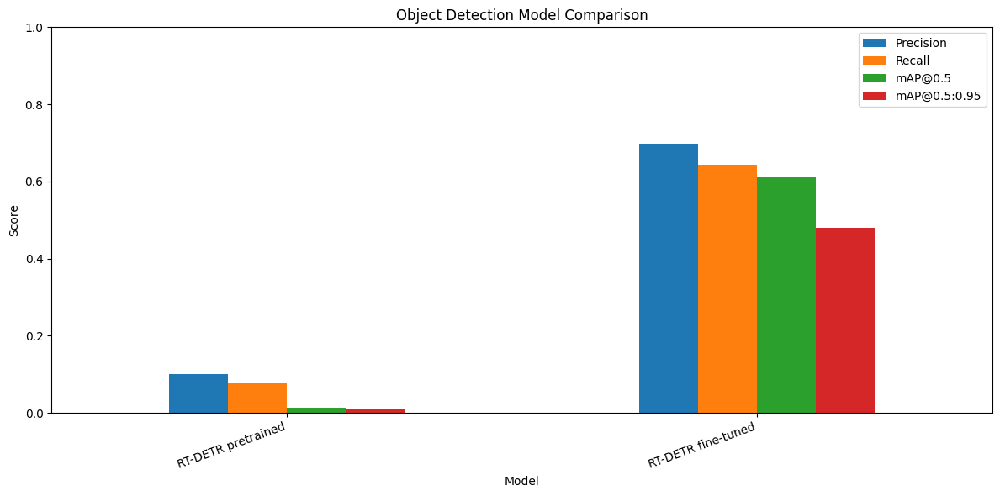

Report status saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/report_status.json
Outputs directory: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs


In [15]:
import json
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

available_results = []

for csv_path in [
    OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv"
]:
    if csv_path.exists():
        available_results.append(pd.read_csv(csv_path))

if available_results:
    comparison_df = pd.concat(
        available_results,
        ignore_index=True
    )

    comparison_df.to_csv(
        OUTPUT_DIR / "model_comparison.csv",
        index=False
    )

    display(comparison_df)

    metric_columns = [
        column for column in
        ["Precision", "Recall", "mAP@0.5", "mAP@0.5:0.95"]
        if column in comparison_df.columns
    ]

    if metric_columns:
        ax = comparison_df.set_index("Model")[metric_columns].plot(
            kind="bar",
            figsize=(12, 6)
        )
        ax.set_ylim(0, 1)
        ax.set_ylabel("Score")
        ax.set_title("Object Detection Model Comparison")
        plt.xticks(rotation=20, ha="right")
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / "model_comparison_metrics.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
else:
    print("No completed quantitative evaluation files were found yet.")

report_status = {
    "dataset": "COCO-format piled-garbage dataset",
    "class_names": class_names,
    "dataset_summary": dataset_summary if "dataset_summary" in globals() else {},
    "completed_result_files": [
        str(path.relative_to(PROJECT_DIR))
        for path in OUTPUT_DIR.rglob("*")
        if path.is_file()
    ],
    "caution": (
        "Only report metrics from successfully completed experiments. "
        "Grounding DINO zero-shot detections must not be presented as "
        "supervised fine-tuning results. DINO fine-tuning is not complete "
        "unless its training, checkpoint, and evaluation are verified."
    )
}

with open(OUTPUT_DIR / "report_status.json", "w", encoding="utf-8") as f:
    json.dump(report_status, f, indent=2, ensure_ascii=False)

print("Report status saved to:", OUTPUT_DIR / "report_status.json")
print("Outputs directory:", OUTPUT_DIR)

# RT-DETR Training Curves

,epoch,time,train/giou_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/giou_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
6,7,227.267,0.39112,0.70356,0.47456,0.26529,0.16667,0.17682,0.10511,0.38807,1.65789,0.86122,0.001337,0.001337,0.001337
7,8,259.471,0.41596,0.61463,0.53654,0.44782,0.61111,0.47169,0.25217,0.44430,1.17238,0.97054,0.001282,0.001282,0.001282
8,9,291.629,0.33006,0.61771,0.49689,0.78645,0.61111,0.66053,0.41992,0.51571,0.94691,1.07057,0.001227,0.001227,0.001227
9,10,323.765,0.43069,0.67050,0.55178,0.76490,0.61111,0.64689,0.36374,0.35932,1.13454,0.86894,0.001172,0.001172,0.001172
10,11,355.745,0.40694,0.71563,0.56487,0.81098,0.50000,0.58762,0.37205,0.51830,1.04488,1.17916,0.001117,0.001117,0.001117


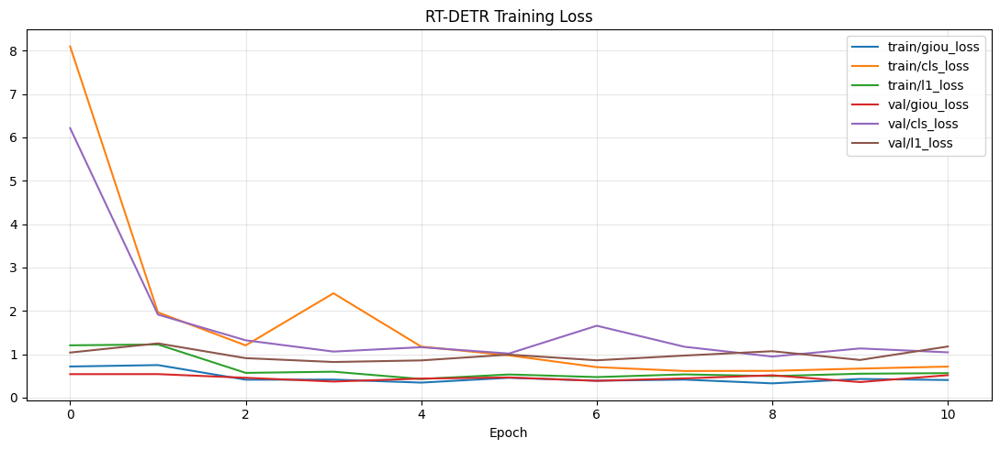

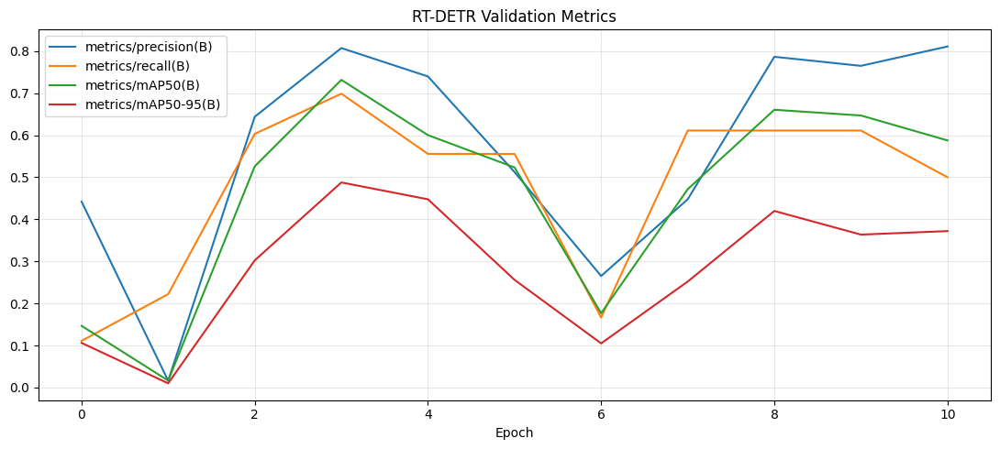

In [16]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RTDETR_HISTORY_PATH = RTDETR_RUN_DIR / "results.csv"
RTDETR_CURVE_DIR = OUTPUT_DIR / "training_curves"
RTDETR_CURVE_DIR.mkdir(parents=True, exist_ok=True)

if RTDETR_HISTORY_PATH.exists():
    history = pd.read_csv(RTDETR_HISTORY_PATH)
    history.columns = [column.strip() for column in history.columns]

    display(history.tail())

    history.to_csv(
        OUTPUT_DIR / "rtdetr_training_history.csv",
        index=False
    )

    columns_lower = {column: column.lower() for column in history.columns}

    loss_columns = [
        column for column in history.columns
        if "loss" in columns_lower[column]
    ]

    metric_columns = [
        column for column in history.columns
        if any(
            key in columns_lower[column]
            for key in ["precision", "recall", "map50", "map50-95"]
        )
    ]

    for selected_columns, title, filename in [
        (loss_columns, "RT-DETR Training Loss", "rtdetr_loss.png"),
        (metric_columns, "RT-DETR Validation Metrics", "rtdetr_metrics.png")
    ]:
        if selected_columns:
            ax = history[selected_columns].plot(figsize=(11, 5))
            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.savefig(
                RTDETR_CURVE_DIR / filename,
                dpi=200,
                bbox_inches="tight"
            )
            plt.show()
            plt.close()
        else:
            print("No columns found for:", title)

else:
    print("RT-DETR training history was not found.")
    print("Expected:", RTDETR_HISTORY_PATH)

# Ground Truth vs RT-DETR Predictions

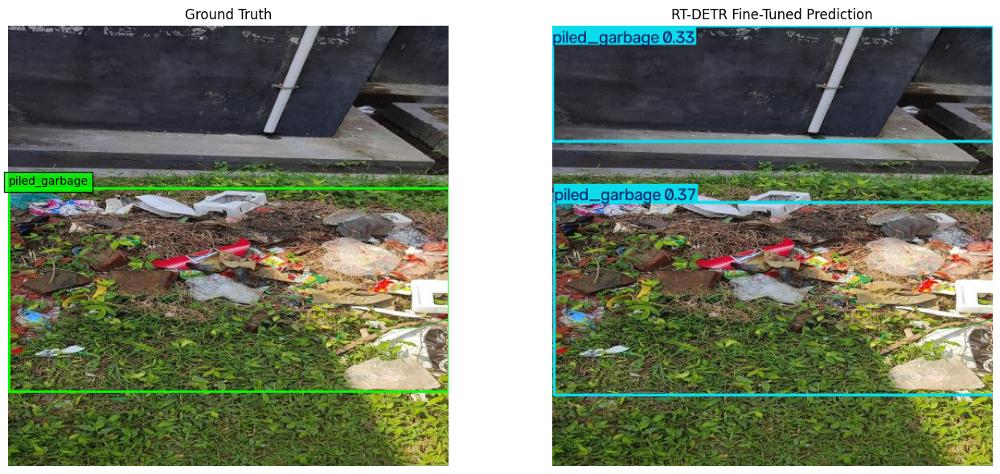

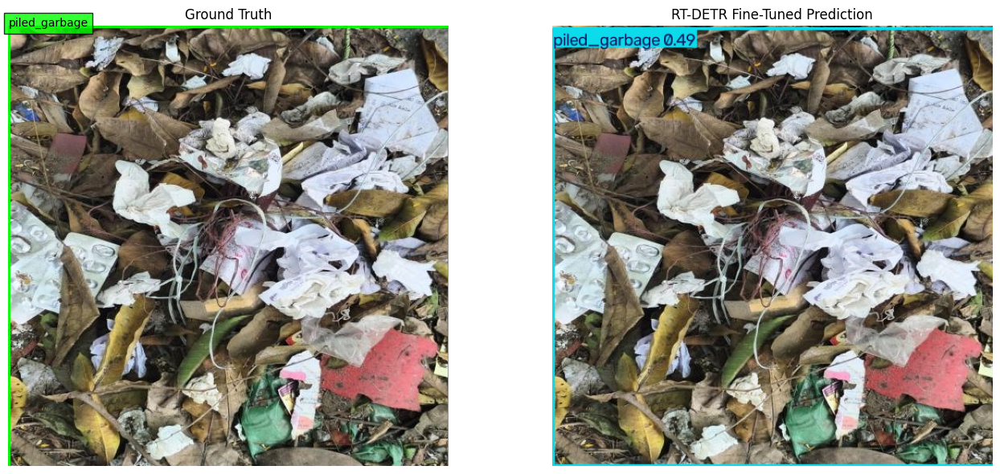

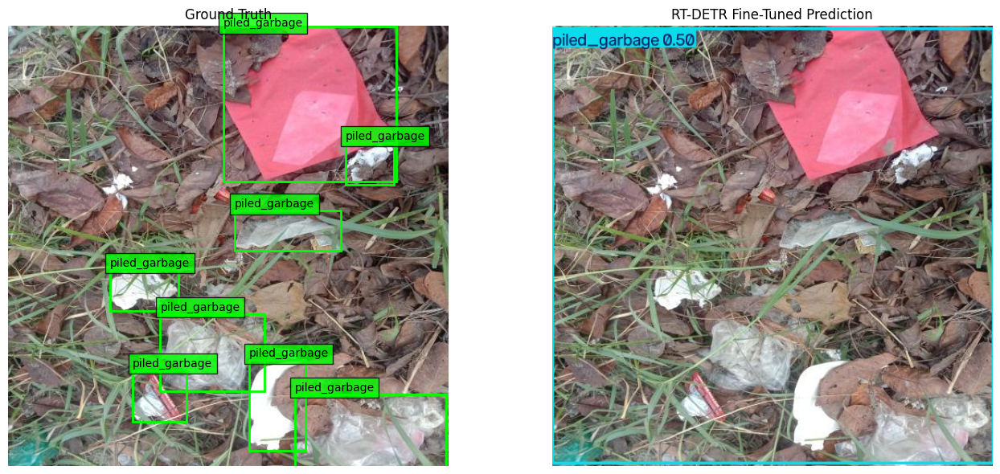

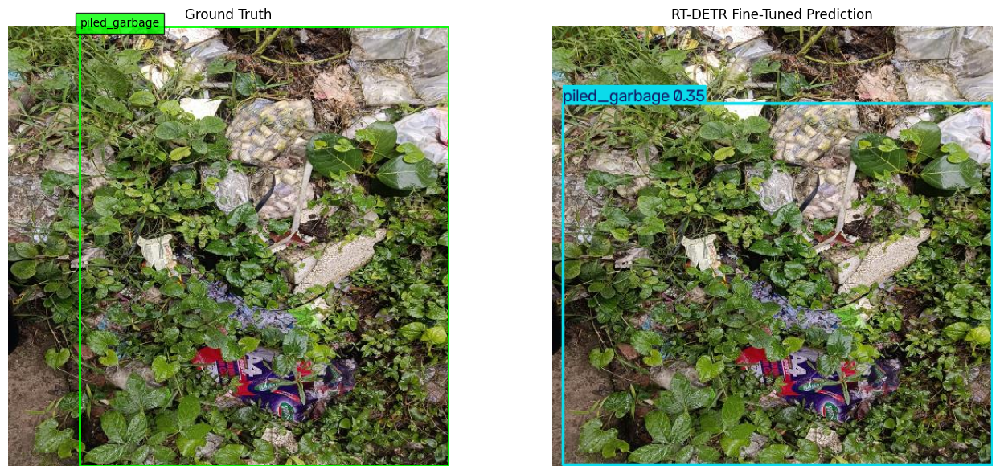

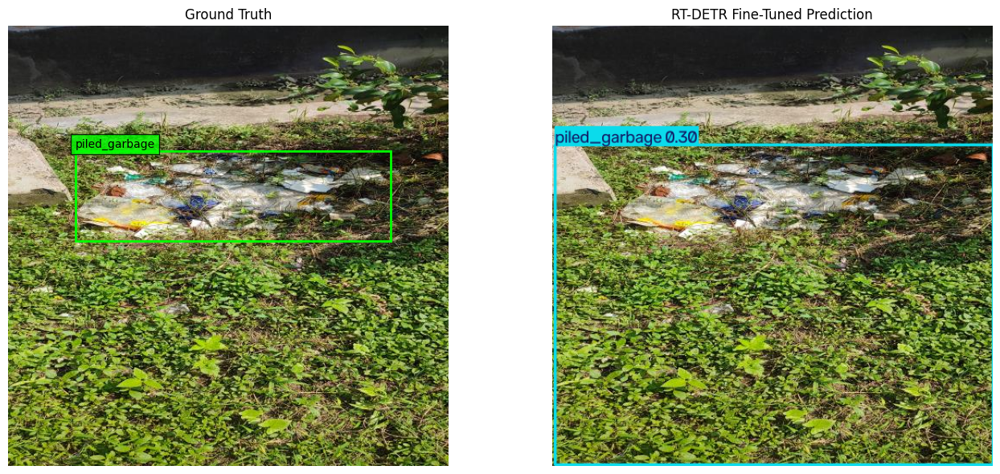

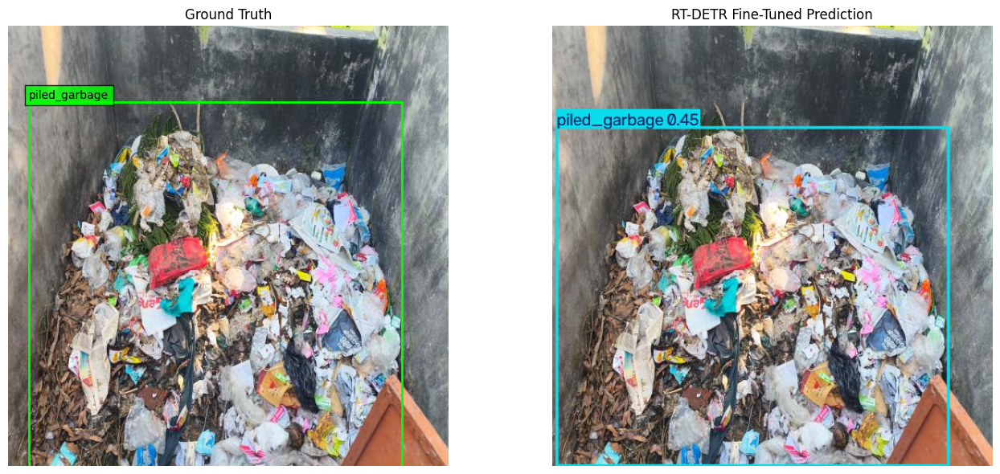

Saved qualitative results to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/qualitative_results


In [17]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import RTDETR

QUALITATIVE_DIR = OUTPUT_DIR / "qualitative_results"
QUALITATIVE_DIR.mkdir(parents=True, exist_ok=True)

test_annotation_path = DATA_DIR / "test" / "_annotations.coco.json"

with open(test_annotation_path, encoding="utf-8") as f:
    test_coco = json.load(f)

test_categories = {
    int(category["id"]): category["name"]
    for category in test_coco["categories"]
}

test_image_records = [
    image_info for image_info in test_coco["images"]
    if (DATA_DIR / "test" / image_info["file_name"]).exists()
]

if not test_image_records:
    print("No readable test images were found.")
elif not RTDETR_WEIGHTS.exists():
    print("RT-DETR fine-tuned checkpoint not found:", RTDETR_WEIGHTS)
else:
    random.seed(42)
    selected_images = random.sample(
        test_image_records,
        min(6, len(test_image_records))
    )

    qualitative_model = RTDETR(str(RTDETR_WEIGHTS))

    for index, image_info in enumerate(selected_images, start=1):
        image_path = DATA_DIR / "test" / image_info["file_name"]

        with Image.open(image_path) as image:
            rgb_image = image.convert("RGB")

        prediction = qualitative_model.predict(
            source=str(image_path),
            imgsz=512,
            conf=0.25,
            device=0 if torch.cuda.is_available() else "cpu",
            verbose=False
        )[0]

        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        axes[0].imshow(rgb_image)
        axes[0].set_title("Ground Truth")

        for ann in test_coco["annotations"]:
            if int(ann["image_id"]) != int(image_info["id"]):
                continue

            x, y, width, height = map(float, ann["bbox"])
            category_name = test_categories.get(
                int(ann["category_id"]), "Unknown"
            )

            axes[0].add_patch(
                patches.Rectangle(
                    (x, y), width, height,
                    linewidth=2,
                    edgecolor="lime",
                    facecolor="none"
                )
            )
            axes[0].text(
                x, max(0, y - 4), category_name,
                color="black",
                bbox={"facecolor": "lime", "alpha": 0.8}
            )

        axes[1].imshow(prediction.plot()[..., ::-1])
        axes[1].set_title("RT-DETR Fine-Tuned Prediction")

        for ax in axes:
            ax.axis("off")

        plt.tight_layout()
        output_path = QUALITATIVE_DIR / f"rtdetr_comparison_{index}.png"
        plt.savefig(output_path, dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    print("Saved qualitative results to:", QUALITATIVE_DIR)

# DETR Evaluation on the Test Set

In [18]:
import json
import time
import torch
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from transformers import AutoImageProcessor, AutoModelForObjectDetection

DETR_EVAL_DIR = OUTPUT_DIR / "detr_evaluation"
DETR_EVAL_DIR.mkdir(parents=True, exist_ok=True)

def evaluate_detr_checkpoint(checkpoint_path, result_name):
    checkpoint_path = Path(checkpoint_path)

    processor = AutoImageProcessor.from_pretrained(checkpoint_path)
    model = AutoModelForObjectDetection.from_pretrained(
        checkpoint_path
    ).to(detr_device)
    model.eval()

    annotation_path = DATA_DIR / "test" / "_annotations.coco.json"
    with open(annotation_path, encoding="utf-8") as f:
        coco_data = json.load(f)

    coco_gt = COCO(str(annotation_path))
    results = []
    inference_times = []
    processed_images = 0

    for image_info in tqdm(coco_data["images"], desc=result_name):
        image_path = DATA_DIR / "test" / image_info["file_name"]

        if not image_path.exists():
            continue

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        inputs = processor(images=image, return_tensors="pt")
        inputs = {
            key: value.to(detr_device) if torch.is_tensor(value) else value
            for key, value in inputs.items()
        }

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.no_grad():
            outputs = model(**inputs)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_times.append(time.perf_counter() - start)

        target_sizes = torch.tensor(
            [[image.height, image.width]],
            device=detr_device
        )

        predictions = processor.post_process_object_detection(
            outputs,
            threshold=0.0,
            target_sizes=target_sizes
        )[0]

        for box, score, label in zip(
            predictions["boxes"].cpu().tolist(),
            predictions["scores"].cpu().tolist(),
            predictions["labels"].cpu().tolist()
        ):
            x1, y1, x2, y2 = box
            width = max(0.0, x2 - x1)
            height = max(0.0, y2 - y1)

            if width <= 0 or height <= 0:
                continue

            results.append({
                "image_id": int(image_info["id"]),
                "category_id": int(label),
                "bbox": [x1, y1, width, height],
                "score": float(score)
            })

        processed_images += 1

    predictions_path = DETR_EVAL_DIR / f"{result_name}_predictions.json"
    with open(predictions_path, "w", encoding="utf-8") as f:
        json.dump(results, f)

    if not results:
        raise RuntimeError(
            f"{result_name}: no predictions were generated; "
            "COCO evaluation cannot proceed."
        )

    coco_dt = coco_gt.loadRes(str(predictions_path))
    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    avg_latency = (
        sum(inference_times) * 1000 / len(inference_times)
        if inference_times else None
    )

    row = {
        "Model": result_name,
        "Images evaluated": processed_images,
        "Precision": None,
        "Recall": None,
        "mAP@0.5": float(evaluator.stats[1]),
        "mAP@0.5:0.95": float(evaluator.stats[0]),
        "Average model inference latency (ms/image)": avg_latency,
        "Model throughput (images/sec)": (
            1000 / avg_latency if avg_latency and avg_latency > 0 else None
        )
    }

    return row

detr_finetuned_row = evaluate_detr_checkpoint(
    DETR_CHECKPOINT,
    "DETR fine-tuned"
)

detr_results_df = pd.DataFrame([detr_finetuned_row])
detr_results_df.to_csv(
    DETR_EVAL_DIR / "detr_test_metrics.csv",
    index=False
)

display(detr_results_df)

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


DETR fine-tuned:   0%|          | 0/18 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.07s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.371
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.475
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.373
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.461
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.416
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.452
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.504
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

,Model,Images evaluated,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Average model inference latency (ms/image),Model throughput (images/sec)
0,DETR fine-tuned,18,None,None,0.475474,0.370917,63.684555,15.702394


# Grounding DINO Qualitative Visualizations

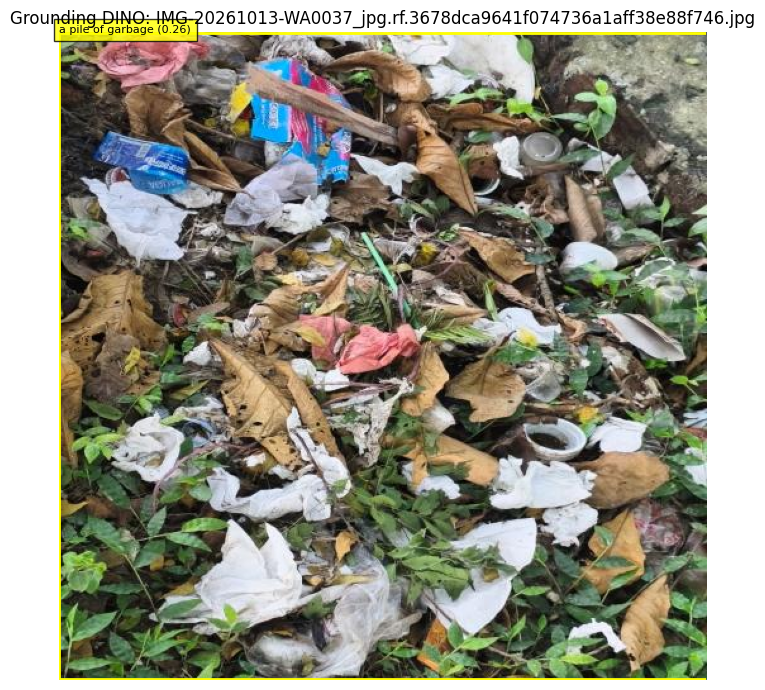

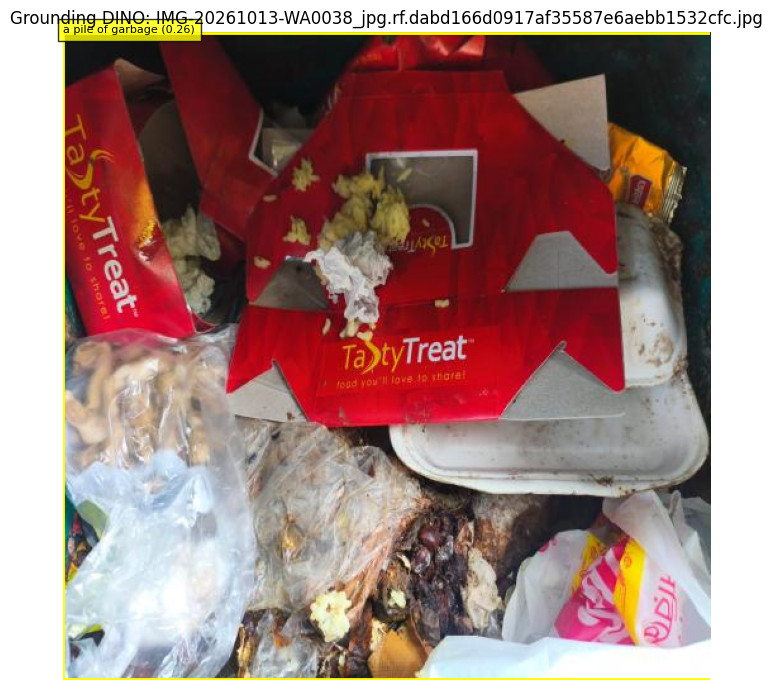

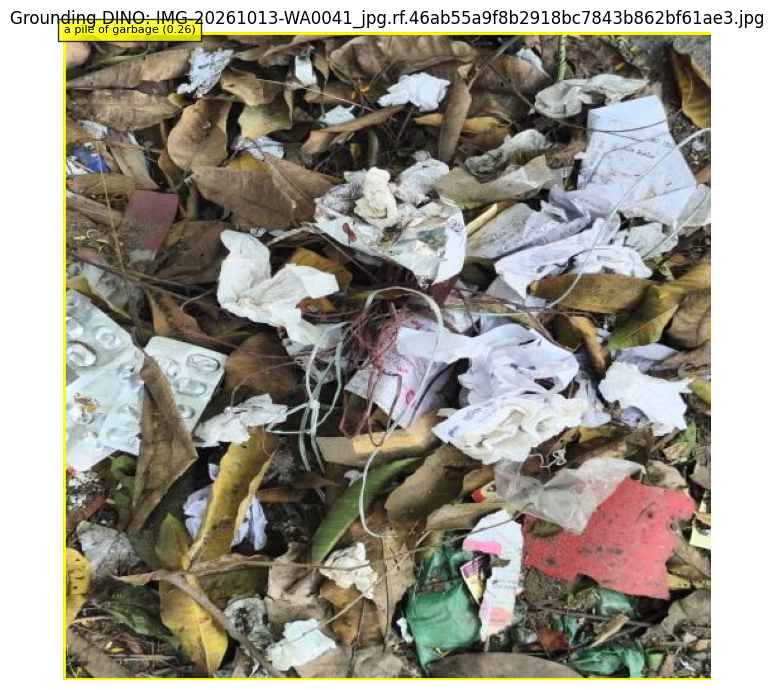

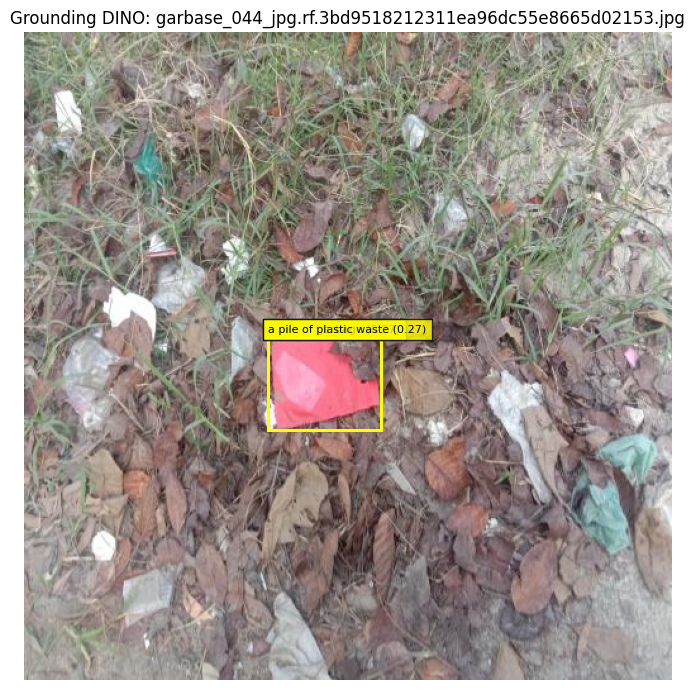

Saved Grounding DINO visualizations to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/grounding_dino/visualizations


In [19]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

GROUNDING_JSON = GROUNDING_DIR / "zero_shot_predictions.json"
GROUNDING_VIS_DIR = GROUNDING_DIR / "visualizations"
GROUNDING_VIS_DIR.mkdir(parents=True, exist_ok=True)

if GROUNDING_JSON.exists():
    grounding_predictions = pd.read_json(GROUNDING_JSON)

    if grounding_predictions.empty:
        print("Grounding DINO produced no detections at the chosen threshold.")
    else:
        for image_name in grounding_predictions["image"].drop_duplicates().head(6):
            image_path = TEST_IMAGES / image_name

            if not image_path.exists():
                continue

            with Image.open(image_path) as image:
                image = image.convert("RGB")

            fig, ax = plt.subplots(figsize=(10, 7))
            ax.imshow(image)

            image_predictions = grounding_predictions[
                grounding_predictions["image"] == image_name
            ]

            for _, row in image_predictions.iterrows():
                box = row["box"]

                if isinstance(box, str):
                    box = json.loads(box)

                x1 = float(box["xmin"])
                y1 = float(box["ymin"])
                x2 = float(box["xmax"])
                y2 = float(box["ymax"])

                ax.add_patch(
                    patches.Rectangle(
                        (x1, y1), x2 - x1, y2 - y1,
                        linewidth=2,
                        edgecolor="yellow",
                        facecolor="none"
                    )
                )

                ax.text(
                    x1, max(0, y1 - 4),
                    f"{row['prompt']} ({row['score']:.2f})",
                    color="black",
                    fontsize=8,
                    bbox={"facecolor": "yellow", "alpha": 0.8}
                )

            ax.set_title(f"Grounding DINO: {image_name}")
            ax.axis("off")
            plt.tight_layout()
            plt.savefig(
                GROUNDING_VIS_DIR / f"{Path(image_name).stem}_grounding.png",
                dpi=200,
                bbox_inches="tight"
            )
            plt.show()
            plt.close(fig)

    print("Saved Grounding DINO visualizations to:", GROUNDING_VIS_DIR)
else:
    print("Grounding DINO prediction JSON is missing:", GROUNDING_JSON)

# Unified Quantitative Comparison

Included: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/rtdetr_baseline_vs_finetuned.csv
Included: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/detr_evaluation/detr_test_metrics.csv


,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image),Images evaluated,Average model inference latency (ms/image),Model throughput (images/sec)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334,NaN,NaN,NaN
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332,NaN,NaN,NaN
2,DETR fine-tuned,NaN,NaN,0.475474,0.370917,NaN,NaN,NaN,18.0,63.684555,15.702394


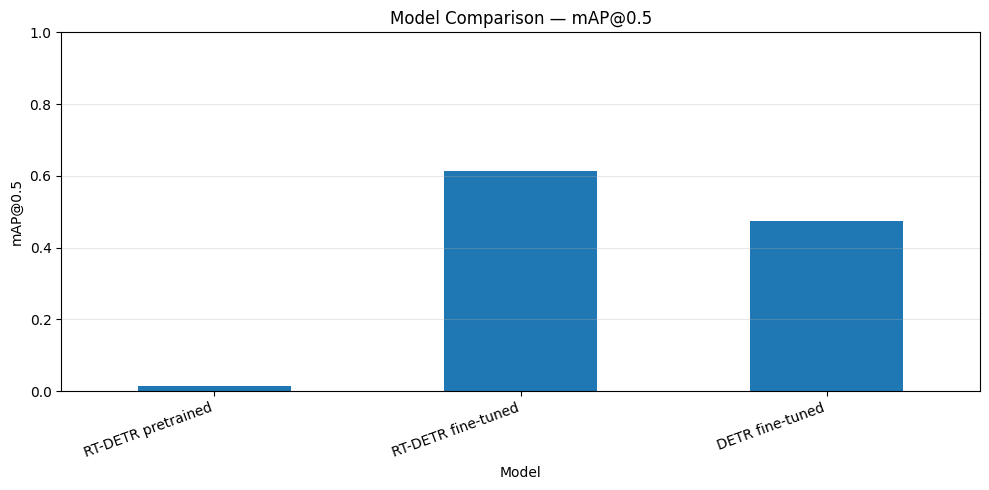

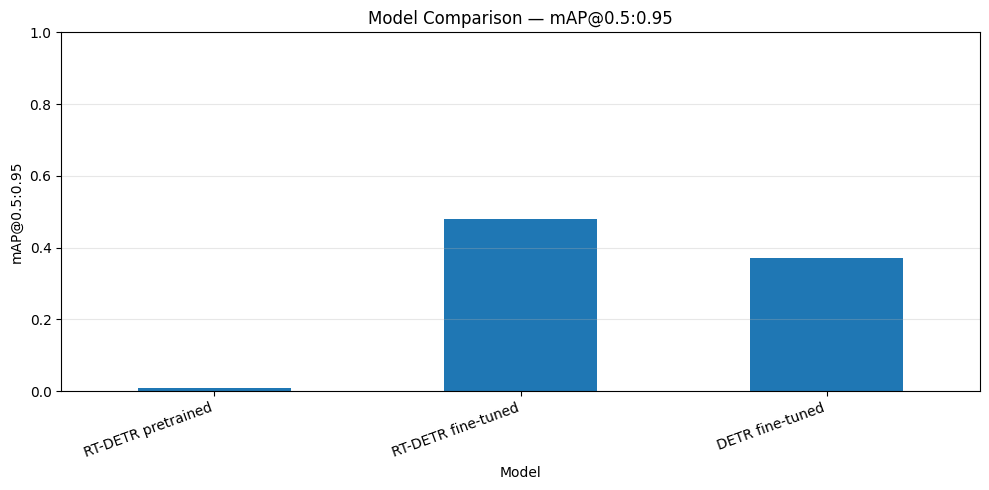

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

COMPARISON_DIR = OUTPUT_DIR / "final_comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

candidate_files = [
    OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
    OUTPUT_DIR / "detr_evaluation" / "detr_test_metrics.csv"
]

available_frames = []

for file_path in candidate_files:
    if file_path.exists():
        frame = pd.read_csv(file_path)
        if not frame.empty:
            available_frames.append(frame)
            print("Included:", file_path)

if available_frames:
    unified_df = pd.concat(available_frames, ignore_index=True, sort=False)
    unified_df = unified_df.drop_duplicates(
        subset=["Model"],
        keep="last"
    )

    unified_df.to_csv(
        COMPARISON_DIR / "unified_model_comparison.csv",
        index=False
    )

    display(unified_df)

    for metric in ["mAP@0.5", "mAP@0.5:0.95"]:
        if metric in unified_df.columns:
            plot_data = unified_df[["Model", metric]].dropna()

            if not plot_data.empty:
                ax = plot_data.set_index("Model")[metric].plot(
                    kind="bar",
                    figsize=(10, 5)
                )
                ax.set_title(f"Model Comparison — {metric}")
                ax.set_ylabel(metric)
                ax.set_ylim(0, 1)
                ax.grid(axis="y", alpha=0.3)
                plt.xticks(rotation=20, ha="right")
                plt.tight_layout()
                plt.savefig(
                    COMPARISON_DIR / f"{metric.replace('@', '_')}.png",
                    dpi=200,
                    bbox_inches="tight"
                )
                plt.show()
                plt.close()
else:
    unified_df = pd.DataFrame()
    print("No saved evaluation CSV files are available yet.")

# DINO Training Status Verification

In [21]:
import json
from pathlib import Path

DINO_STATUS_FILE = OUTPUT_DIR / "dino_status.json"
DINO_CHECKPOINT_DIR = OUTPUT_DIR / "dino_checkpoints"
DINO_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_extensions = {".pth", ".pt", ".ckpt"}
dino_checkpoints = [
    path for path in DINO_CHECKPOINT_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in checkpoint_extensions
]

if DINO_STATUS_FILE.exists():
    with open(DINO_STATUS_FILE, encoding="utf-8") as f:
        dino_status = json.load(f)
else:
    dino_status = {"model": "DINO"}

dino_status["checkpoint_directory"] = str(DINO_CHECKPOINT_DIR)
dino_status["checkpoints_found"] = [
    str(path) for path in dino_checkpoints
]

if dino_checkpoints:
    dino_status["training_status"] = (
        "checkpoint_found_but_training_and_evaluation_require_verification"
    )
else:
    dino_status["training_status"] = "not_completed_or_checkpoint_not_found"

with open(DINO_STATUS_FILE, "w", encoding="utf-8") as f:
    json.dump(dino_status, f, indent=2)

print(json.dumps(dino_status, indent=2))

{
  "model": "DINO",
  "repository": "/media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/external/DINO",
  "setup_status": "repository_exists",
  "training_status": "not_completed_or_checkpoint_not_found",
  "note": "Official DINO training requires its compatible configuration, pretrained checkpoint, dependencies, and compiled operators.",
  "readme_exists": true,
  "config_directory_exists": true,
  "available_configs": [
    "config/DINO/DINO_5scale.py",
    "config/DINO/DINO_4scale_convnext.py",
    "config/DINO/coco_transformer.py",
    "config/DINO/DINO_4scale.py",
    "config/DINO/DINO_4scale_swin.py"
  ],
  "checkpoint_directory": "/media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_checkpoints",
  "checkpoints_found": []
}


# Final Summary and Output Inventory

In [22]:
import json
import pandas as pd
from pathlib import Path

FINAL_SUMMARY_PATH = OUTPUT_DIR / "final_report_summary.csv"
INVENTORY_PATH = OUTPUT_DIR / "output_inventory.csv"

summary = {
    "Dataset": "Piled-garbage object detection",
    "Train images": dataset_summary.get("train", {}).get("images_in_annotations", None),
    "Validation images": dataset_summary.get("valid", {}).get("images_in_annotations", None),
    "Test images": dataset_summary.get("test", {}).get("images_in_annotations", None),
    "Classes": ", ".join(class_names),
    "GPU": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "RT-DETR fine-tuning": (
        "checkpoint exists" if RTDETR_WEIGHTS.exists() else "not completed"
    ),
    "DETR fine-tuning": (
        "checkpoint exists" if DETR_CHECKPOINT.exists() else "not completed"
    ),
    "DINO fine-tuning": (
        dino_status.get("training_status", "not verified")
    ),
    "Grounding DINO": (
        "prediction file exists"
        if GROUNDING_JSON.exists()
        else "not completed"
    ),
    "Unified comparison": (
        "available" if (COMPARISON_DIR / "unified_model_comparison.csv").exists()
        else "not available"
    )
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Value"]
)

summary_df.to_csv(FINAL_SUMMARY_PATH, index=False)
display(summary_df)

inventory = [
    {
        "file": str(path.relative_to(PROJECT_DIR)),
        "size_bytes": path.stat().st_size
    }
    for path in sorted(OUTPUT_DIR.rglob("*"))
    if path.is_file()
]

inventory_df = pd.DataFrame(inventory)
inventory_df.to_csv(INVENTORY_PATH, index=False)
display(inventory_df)

print("Final summary:", FINAL_SUMMARY_PATH)
print("Output inventory:", INVENTORY_PATH)

,Item,Value
0,Dataset,Piled-garbage object detection
1,Train images,80
2,Validation images,18
3,Test images,18
4,Classes,"Piled-Garbage-Detection, piled_garbage"
5,GPU,NVIDIA GeForce GTX 1070
6,RT-DETR fine-tuning,checkpoint exists
7,DETR fine-tuning,checkpoint exists
8,DINO fine-tuning,not_completed_or_checkpoint_not_found
9,Grounding DINO,prediction file exists


,file,size_bytes
0,outputs/augmentation_config.json,259
1,outputs/class_distribution.csv,39
2,outputs/dataset_audit/annotation_errors.json,2
3,outputs/dataset_audit/class_summary.json,127
4,outputs/dataset_audit/dataset_summary.json,871
...,...,...
384,outputs/yolo_dataset/labels/valid/garbase_041_...,37
385,outputs/yolo_dataset/labels/valid/garbase_046_...,37
386,outputs/yolo_dataset/labels/valid/garbase_051_...,37
387,outputs/yolo_dataset/labels/valid/garbase_056_...,37


Final summary: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_report_summary.csv
Output inventory: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/output_inventory.csv


# Validate Class Mapping and COCO Categories

In [23]:
import json
from pathlib import Path

split_categories = {}

for split in ["train", "valid", "test"]:
    annotation_path = DATA_DIR / split / "_annotations.coco.json"

    with open(annotation_path, encoding="utf-8") as f:
        coco = json.load(f)

    categories = sorted(
        coco["categories"],
        key=lambda category: int(category["id"])
    )

    split_categories[split] = {
        int(category["id"]): category["name"]
        for category in categories
    }

reference_categories = split_categories["train"]

for split in ["valid", "test"]:
    if split_categories[split] != reference_categories:
        raise ValueError(
            f"Category mapping differs in {split}. "
            f"Train={reference_categories}, "
            f"{split}={split_categories[split]}"
        )

category_to_label = {
    category_id: index
    for index, category_id in enumerate(reference_categories.keys())
}
label_to_category = {
    label: category_id
    for category_id, label in category_to_label.items()
}

class_names = [
    reference_categories[category_id]
    for category_id in reference_categories
]

print("Verified classes:", class_names)
print("COCO category ID to model label:", category_to_label)
print("Model label to COCO category ID:", label_to_category)
print("STEP 19 COMPLETED")

Verified classes: ['Piled-Garbage-Detection', 'piled_garbage']
COCO category ID to model label: {0: 0, 1: 1}
Model label to COCO category ID: {0: 0, 1: 1}
STEP 19 COMPLETED


# Corrected DETR Test Evaluation

In [24]:
import json
import time
import torch
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from transformers import AutoImageProcessor, AutoModelForObjectDetection

DETR_EVAL_DIR = OUTPUT_DIR / "detr_evaluation"
DETR_EVAL_DIR.mkdir(parents=True, exist_ok=True)

def evaluate_detr_checkpoint(checkpoint_path, result_name):
    checkpoint_path = Path(checkpoint_path)

    processor = AutoImageProcessor.from_pretrained(checkpoint_path)
    model = AutoModelForObjectDetection.from_pretrained(
        checkpoint_path
    ).to(detr_device)
    model.eval()

    annotation_path = DATA_DIR / "test" / "_annotations.coco.json"
    coco_gt = COCO(str(annotation_path))

    with open(annotation_path, encoding="utf-8") as f:
        coco_data = json.load(f)

    results = []
    inference_times = []
    processed_images = 0

    for image_info in tqdm(coco_data["images"], desc=result_name):
        image_path = DATA_DIR / "test" / image_info["file_name"]

        if not image_path.exists():
            continue

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        inputs = processor(images=image, return_tensors="pt")
        inputs = {
            key: value.to(detr_device) if torch.is_tensor(value) else value
            for key, value in inputs.items()
        }

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.no_grad():
            outputs = model(**inputs)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_times.append(time.perf_counter() - start)

        target_sizes = torch.tensor(
            [[image.height, image.width]],
            device=detr_device
        )

        predictions = processor.post_process_object_detection(
            outputs,
            threshold=0.0,
            target_sizes=target_sizes
        )[0]

        for box, score, label in zip(
            predictions["boxes"].cpu().tolist(),
            predictions["scores"].cpu().tolist(),
            predictions["labels"].cpu().tolist()
        ):
            if int(label) not in label_to_category:
                continue

            x1, y1, x2, y2 = box
            width = max(0.0, x2 - x1)
            height = max(0.0, y2 - y1)

            if width <= 0 or height <= 0:
                continue

            results.append({
                "image_id": int(image_info["id"]),
                "category_id": int(label_to_category[int(label)]),
                "bbox": [x1, y1, width, height],
                "score": float(score)
            })

        processed_images += 1

    if not results:
        raise RuntimeError(
            f"{result_name}: no valid predictions were generated."
        )

    predictions_path = (
        DETR_EVAL_DIR / f"{result_name.replace(' ', '_')}_predictions.json"
    )

    with open(predictions_path, "w", encoding="utf-8") as f:
        json.dump(results, f)

    coco_dt = coco_gt.loadRes(str(predictions_path))
    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    avg_latency = (
        sum(inference_times) * 1000 / len(inference_times)
        if inference_times else None
    )

    return {
        "Model": result_name,
        "Images evaluated": processed_images,
        "mAP@0.5": float(evaluator.stats[1]),
        "mAP@0.5:0.95": float(evaluator.stats[0]),
        "Average model latency (ms/image)": avg_latency,
        "Model throughput (images/sec)": (
            1000 / avg_latency if avg_latency and avg_latency > 0 else None
        )
    }

detr_finetuned_row = evaluate_detr_checkpoint(
    DETR_CHECKPOINT,
    "DETR fine-tuned"
)

detr_results_df = pd.DataFrame([detr_finetuned_row])
detr_results_df.to_csv(
    DETR_EVAL_DIR / "detr_test_metrics.csv",
    index=False
)

display(detr_results_df)

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!


DETR fine-tuned:   0%|          | 0/18 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.06s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.371
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.475
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.373
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.461
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.416
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.452
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.504
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

,Model,Images evaluated,mAP@0.5,mAP@0.5:0.95,Average model latency (ms/image),Model throughput (images/sec)
0,DETR fine-tuned,18,0.475474,0.370917,62.507599,15.998055


# Prepare COCO Dataset for Official DINO

In [25]:
import json
import shutil
from pathlib import Path

DINO_DATA_DIR = OUTPUT_DIR / "dino_coco"
DINO_ANNOTATION_DIR = DINO_DATA_DIR / "annotations"

DINO_ANNOTATION_DIR.mkdir(parents=True, exist_ok=True)

dino_split_names = {
    "train": "train2017",
    "valid": "val2017",
    "test": "test2017"
}

for source_split, target_split in dino_split_names.items():
    source_dir = DATA_DIR / source_split
    target_dir = DINO_DATA_DIR / target_split
    target_dir.mkdir(parents=True, exist_ok=True)

    annotation_path = source_dir / "_annotations.coco.json"

    with open(annotation_path, encoding="utf-8") as f:
        coco = json.load(f)

    converted = dict(coco)

    converted["categories"] = [
        {
            "id": index + 1,
            "name": category["name"],
            "supercategory": category.get("supercategory", "object")
        }
        for index, category in enumerate(
            sorted(coco["categories"], key=lambda item: int(item["id"]))
        )
    ]

    old_to_new = {
        int(old["id"]): index + 1
        for index, old in enumerate(
            sorted(coco["categories"], key=lambda item: int(item["id"]))
        )
    }

    converted["annotations"] = [
        {
            **ann,
            "category_id": old_to_new[int(ann["category_id"])]
        }
        for ann in coco["annotations"]
        if int(ann["category_id"]) in old_to_new
    ]

    converted["images"] = [
        {
            **image_info,
            "file_name": Path(image_info["file_name"]).name
        }
        for image_info in coco["images"]
    ]

    for image_info in coco["images"]:
        source_image = source_dir / image_info["file_name"]
        target_image = target_dir / Path(image_info["file_name"]).name

        if source_image.exists() and not target_image.exists():
            shutil.copy2(source_image, target_image)

    target_annotation_path = (
        DINO_ANNOTATION_DIR / f"instances_{target_split}.json"
    )

    with open(target_annotation_path, "w", encoding="utf-8") as f:
        json.dump(converted, f, indent=2)

    print(
        source_split,
        "images:", len(converted["images"]),
        "annotations:", len(converted["annotations"]),
        "saved:", target_annotation_path
    )

print("DINO COCO directory prepared:", DINO_DATA_DIR)

train images: 80 annotations: 90 saved: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_coco/annotations/instances_train2017.json
valid images: 18 annotations: 18 saved: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_coco/annotations/instances_val2017.json
test images: 18 annotations: 25 saved: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_coco/annotations/instances_test2017.json
DINO COCO directory prepared: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_coco


# Inspect DINO Configuration and Training Dependencies

In [26]:
import json
import subprocess
import sys
from pathlib import Path

DINO_DIR = PROJECT_DIR / "external" / "DINO"
DINO_CONFIG = DINO_DIR / "config" / "DINO" / "DINO_4scale.py"
DINO_OPS_DIR = DINO_DIR / "models" / "dino" / "ops"

DINO_SETUP_REPORT = OUTPUT_DIR / "dino_setup_report.json"

setup_report = {
    "repository_exists": DINO_DIR.exists(),
    "config_exists": DINO_CONFIG.exists(),
    "ops_directory_exists": DINO_OPS_DIR.exists(),
    "python": sys.version,
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available()
}

if DINO_DIR.exists():
    setup_report["main_py_exists"] = (DINO_DIR / "main.py").exists()
    setup_report["requirements_exists"] = (
        DINO_DIR / "requirements.txt"
    ).exists()

if DINO_CONFIG.exists():
    config_text = DINO_CONFIG.read_text(encoding="utf-8")
    setup_report["config_has_num_classes"] = "num_classes" in config_text
    setup_report["config_has_dn_labelbook_size"] = (
        "dn_labelbook_size" in config_text
        or "dn_labelbook" in config_text
    )

with open(DINO_SETUP_REPORT, "w", encoding="utf-8") as f:
    json.dump(setup_report, f, indent=2)

print(json.dumps(setup_report, indent=2))
print("Saved:", DINO_SETUP_REPORT)

if not DINO_CONFIG.exists():
    print(
        "\nDINO training cannot start: the expected official configuration "
        "was not found. Check the repository and its config directory."
    )

{
  "repository_exists": true,
  "config_exists": true,
  "ops_directory_exists": true,
  "python": "3.10.20 (main, Jun 11 2026, 15:17:37) [GCC 14.3.0]",
  "pytorch": "2.7.1+cu126",
  "cuda_available": true,
  "main_py_exists": true,
  "requirements_exists": true,
  "config_has_num_classes": true,
  "config_has_dn_labelbook_size": true
}
Saved: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/dino_setup_report.json


# DINO Fine-Tuning Command Preparation

In [27]:
import subprocess
from pathlib import Path

DINO_DIR = PROJECT_DIR / "external" / "DINO"
DINO_CONFIG = DINO_DIR / "config" / "DINO" / "DINO_4scale.py"
DINO_OUTPUT_DIR = OUTPUT_DIR / "dino_training"
DINO_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DINO_PRETRAINED_CHECKPOINT = (
    PROJECT_DIR / "pretrained_weights" / "dino_pretrained.pth"
)

if not DINO_DIR.exists():
    print("Official DINO repository is missing:", DINO_DIR)

elif not DINO_CONFIG.exists():
    print("Official DINO configuration is missing:", DINO_CONFIG)

elif not DINO_PRETRAINED_CHECKPOINT.exists():
    print(
        "DINO fine-tuning was not started because the pretrained checkpoint "
        "is missing."
    )
    print("Expected checkpoint:", DINO_PRETRAINED_CHECKPOINT)
    print(
        "Obtain a compatible checkpoint from the official DINO model zoo, "
        "then place it at the expected path."
    )

else:
    dino_command = [
        sys.executable,
        "main.py",
        "--output_dir", str(DINO_OUTPUT_DIR),
        "-c", str(DINO_CONFIG),
        "--coco_path", str(DINO_DATA_DIR),
        "--pretrain_model_path", str(DINO_PRETRAINED_CHECKPOINT),
        "--finetune_ignore", "label_enc.weight", "class_embed",
        "--options",
        f"num_classes={len(class_names)}",
        f"dn_labelbook_size={len(class_names) + 1}",
        "batch_size=1",
        "num_workers=0",
        "epochs=12"
    ]

    print("DINO training command:")
    print(" ".join(dino_command))

    print(
        "\nThe command is prepared but has not been executed. "
        "Review the repository's config and custom dataset integration "
        "before launching a potentially long GPU training run."
    )

DINO fine-tuning was not started because the pretrained checkpoint is missing.
Expected checkpoint: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/pretrained_weights/dino_pretrained.pth
Obtain a compatible checkpoint from the official DINO model zoo, then place it at the expected path.


# Verify Training Artifacts and Final Evaluation Files

In [28]:
import json
import pandas as pd
from pathlib import Path

verification = []

artifacts_to_check = {
    "RT-DETR fine-tuned checkpoint": RTDETR_WEIGHTS,
    "DETR fine-tuned checkpoint": DETR_CHECKPOINT,
    "DETR test metrics": DETR_EVAL_DIR / "detr_test_metrics.csv",
    "RT-DETR comparison metrics": OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
    "Grounding DINO predictions": GROUNDING_DIR / "zero_shot_predictions.json",
    "DINO setup report": OUTPUT_DIR / "dino_setup_report.json"
}

for name, path in artifacts_to_check.items():
    exists = path.exists()

    verification.append({
        "Artifact": name,
        "Path": str(path),
        "Exists": exists,
        "Status": "Available" if exists else "Missing"
    })

verification_df = pd.DataFrame(verification)
verification_df.to_csv(
    OUTPUT_DIR / "artifact_verification.csv",
    index=False
)

display(verification_df)

print("Verification report:", OUTPUT_DIR / "artifact_verification.csv")

,Artifact,Path,Exists,Status
0,RT-DETR fine-tuned checkpoint,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,Available
1,DETR fine-tuned checkpoint,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,Available
2,DETR test metrics,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,Available
3,RT-DETR comparison metrics,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,Available
4,Grounding DINO predictions,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,Available
5,DINO setup report,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,Available


Verification report: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/artifact_verification.csv


# Evaluate DETR and RT-DETR Results

In [29]:

from pathlib import Path
import pandas as pd

RESULT_FILES = [
    OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
    OUTPUT_DIR / "detr_evaluation" / "detr_test_metrics.csv",
    OUTPUT_DIR / "comparison_results.csv",
]

available_results = []

for result_file in RESULT_FILES:
    if result_file.exists():
        df = pd.read_csv(result_file)
        df["source_file"] = result_file.name
        available_results.append(df)
        print(f"Loaded: {result_file.name} — {len(df)} row(s)")
    else:
        print(f"Not available: {result_file.name}")

if available_results:
    combined_results = pd.concat(
        available_results, ignore_index=True, sort=False
    )
    combined_path = OUTPUT_DIR / "combined_evaluation_results.csv"
    combined_results.to_csv(combined_path, index=False)

    print("\nCombined evaluation results:")
    display(combined_results)
    print(f"\nSaved to: {combined_path}")
else:
    print("No evaluation CSV files were found. Run the evaluation cells first.")


Loaded: rtdetr_baseline_vs_finetuned.csv — 2 row(s)
Loaded: detr_test_metrics.csv — 1 row(s)
Not available: comparison_results.csv

Combined evaluation results:


,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image),source_file,Images evaluated,Average model latency (ms/image),Model throughput (images/sec)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334,rtdetr_baseline_vs_finetuned.csv,NaN,NaN,NaN
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332,rtdetr_baseline_vs_finetuned.csv,NaN,NaN,NaN
2,DETR fine-tuned,NaN,NaN,0.475474,0.370917,NaN,NaN,NaN,detr_test_metrics.csv,18.0,62.507599,15.998055



Saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/combined_evaluation_results.csv


# Plot Available Evaluation Metrics

In [30]:

import matplotlib.pyplot as plt
import pandas as pd

results_path = OUTPUT_DIR / "combined_evaluation_results.csv"

if results_path.exists():
    results_df = pd.read_csv(results_path)
    print("Available columns:", results_df.columns.tolist())

    metric_candidates = [
        "mAP50-95", "map", "mAP", "metrics/mAP50-95(B)",
        "mAP50", "metrics/mAP50(B)", "AP"
    ]

    metric_columns = [
        column for column in metric_candidates
        if column in results_df.columns
    ]

    if metric_columns:
        for metric in metric_columns:
            numeric_values = pd.to_numeric(
                results_df[metric], errors="coerce"
            )
            valid = numeric_values.notna()

            if valid.any():
                plot_df = results_df.loc[valid].copy()
                plot_df[metric] = numeric_values.loc[valid]

                label_column = next(
                    (
                        column for column in
                        ["model_name", "model", "Model", "name"]
                        if column in plot_df.columns
                    ),
                    None
                )

                if label_column is None:
                    plot_df["display_label"] = (
                        plot_df["source_file"].astype(str)
                        if "source_file" in plot_df.columns
                        else plot_df.index.astype(str)
                    )
                    label_column = "display_label"

                plt.figure(figsize=(9, 5))
                plt.bar(
                    plot_df[label_column].astype(str),
                    plot_df[metric]
                )
                plt.title(f"Evaluation Metric: {metric}")
                plt.xlabel("Model or Result")
                plt.ylabel(metric)
                plt.xticks(rotation=30, ha="right")
                plt.tight_layout()
                plt.show()
    else:
        print(
            "No recognized mAP column was found. "
            "Use the column names printed above to select the correct metric."
        )
else:
    print("Run Cell 25 first to create the combined results file.")


Available columns: ['Model', 'Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95', 'Measured average latency (ms/image)', 'Measured throughput (images/sec)', 'Ultralytics inference time (ms/image)', 'source_file', 'Images evaluated', 'Average model latency (ms/image)', 'Model throughput (images/sec)']
No recognized mAP column was found. Use the column names printed above to select the correct metric.


# Plot Available Evaluation Metrics

In [31]:

import matplotlib.pyplot as plt
import pandas as pd

results_path = OUTPUT_DIR / "combined_evaluation_results.csv"

if results_path.exists():
    results_df = pd.read_csv(results_path)
    print("Available columns:", results_df.columns.tolist())

    metric_candidates = [
        "mAP50-95", "map", "mAP", "metrics/mAP50-95(B)",
        "mAP50", "metrics/mAP50(B)", "AP"
    ]

    metric_columns = [
        column for column in metric_candidates
        if column in results_df.columns
    ]

    if metric_columns:
        for metric in metric_columns:
            numeric_values = pd.to_numeric(
                results_df[metric], errors="coerce"
            )
            valid = numeric_values.notna()

            if valid.any():
                plot_df = results_df.loc[valid].copy()
                plot_df[metric] = numeric_values.loc[valid]

                label_column = next(
                    (
                        column for column in
                        ["model_name", "model", "Model", "name"]
                        if column in plot_df.columns
                    ),
                    None
                )

                if label_column is None:
                    plot_df["display_label"] = (
                        plot_df["source_file"].astype(str)
                        if "source_file" in plot_df.columns
                        else plot_df.index.astype(str)
                    )
                    label_column = "display_label"

                plt.figure(figsize=(9, 5))
                plt.bar(
                    plot_df[label_column].astype(str),
                    plot_df[metric]
                )
                plt.title(f"Evaluation Metric: {metric}")
                plt.xlabel("Model or Result")
                plt.ylabel(metric)
                plt.xticks(rotation=30, ha="right")
                plt.tight_layout()
                plt.show()
    else:
        print(
            "No recognized mAP column was found. "
            "Use the column names printed above to select the correct metric."
        )
else:
    print("Run Cell 25 first to create the combined results file.")


Available columns: ['Model', 'Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95', 'Measured average latency (ms/image)', 'Measured throughput (images/sec)', 'Ultralytics inference time (ms/image)', 'source_file', 'Images evaluated', 'Average model latency (ms/image)', 'Model throughput (images/sec)']
No recognized mAP column was found. Use the column names printed above to select the correct metric.


# Grounding DINO Qualitative Results

In [32]:

import json

grounding_dir = OUTPUT_DIR / "grounding_dino"
prediction_file = grounding_dir / "zero_shot_predictions.json"

if prediction_file.exists():
    with open(prediction_file, "r", encoding="utf-8") as file:
        grounding_predictions = json.load(file)

    print("Grounding DINO prediction file found.")
    print("Prediction data type:", type(grounding_predictions).__name__)

    if isinstance(grounding_predictions, dict):
        print("Top-level keys:", list(grounding_predictions.keys())[:20])
    elif isinstance(grounding_predictions, list):
        print("Number of records:", len(grounding_predictions))
        if grounding_predictions:
            print("First record:")
            print(json.dumps(grounding_predictions[0], indent=2)[:3000])

    print("\nUse these predictions for qualitative examples.")
    print("Do not report custom-dataset mAP unless predictions are")
    print("converted to the correct COCO format and evaluated properly.")
else:
    print("Grounding DINO prediction file not found.")
    print("Run the Grounding DINO inference cell first.")


Grounding DINO prediction file found.
Prediction data type: list
Number of records: 5
First record:
{
  "image": "IMG-20261013-WA0037_jpg.rf.3678dca9641f074736a1aff38e88f746.jpg",
  "prompt": "a pile of garbage",
  "score": 0.2635758221,
  "box": {
    "xmin": 0,
    "ymin": 0,
    "xmax": 512,
    "ymax": 511
  },
  "latency_ms": 1471.4192930041
}

Use these predictions for qualitative examples.
Do not report custom-dataset mAP unless predictions are
converted to the correct COCO format and evaluated properly.


# Verify Final Artifacts

In [33]:

from pathlib import Path
import pandas as pd

important_paths = {
    "RT-DETR best checkpoint": OUTPUT_DIR / "rtdetr" / "best.pt",
    "RT-DETR evaluation": OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
    "DETR checkpoint": OUTPUT_DIR / "detr" / "fine_tuned",
    "DETR test metrics": OUTPUT_DIR / "detr_evaluation" / "detr_test_metrics.csv",
    "Grounding DINO predictions": OUTPUT_DIR / "grounding_dino" / "zero_shot_predictions.json",
    "DINO setup report": OUTPUT_DIR / "dino_setup_report.json",
    "Combined results": OUTPUT_DIR / "combined_evaluation_results.csv",
}

artifact_rows = []

for name, path in important_paths.items():
    exists = path.exists()
    if exists and path.is_file():
        size_mb = round(path.stat().st_size / (1024 * 1024), 2)
    else:
        size_mb = None

    artifact_rows.append({
        "Artifact": name,
        "Path": str(path),
        "Exists": exists,
        "Size_MB": size_mb
    })

artifact_df = pd.DataFrame(artifact_rows)
display(artifact_df)

verification_path = OUTPUT_DIR / "final_artifact_verification.csv"
artifact_df.to_csv(verification_path, index=False)

print(f"Verification saved to: {verification_path}")


,Artifact,Path,Exists,Size_MB
0,RT-DETR best checkpoint,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,63.12
1,RT-DETR evaluation,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,0.00
2,DETR checkpoint,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,NaN
3,DETR test metrics,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,0.00
4,Grounding DINO predictions,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,0.00
5,DINO setup report,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,0.00
6,Combined results,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,True,0.00


Verification saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_artifact_verification.csv


# Final Project Status

In [34]:

print("OBJECT DETECTION PROJECT STATUS")
print("=" * 45)

checks = {
    "Dataset prepared": (OUTPUT_DIR / "yolo_dataset").exists(),
    "RT-DETR checkpoint": (OUTPUT_DIR / "rtdetr" / "best.pt").exists(),
    "DETR checkpoint": (OUTPUT_DIR / "detr" / "fine_tuned").exists(),
    "Grounding DINO predictions": (
        OUTPUT_DIR / "grounding_dino" / "zero_shot_predictions.json"
    ).exists(),
    "DINO setup report": (OUTPUT_DIR / "dino_setup_report.json").exists(),
    "Combined evaluation CSV": (
        OUTPUT_DIR / "combined_evaluation_results.csv"
    ).exists(),
}

for task, completed in checks.items():
    print(f"{'[FOUND]' if completed else '[MISSING]'} {task}")

print("\nImportant:")
print("- A checkpoint existing does not guarantee good detection performance.")
print("- DINO setup does not mean DINO fine-tuning is complete.")
print("- Only measured results should be included in the report.")


OBJECT DETECTION PROJECT STATUS
[FOUND] Dataset prepared
[FOUND] RT-DETR checkpoint
[FOUND] DETR checkpoint
[FOUND] Grounding DINO predictions
[FOUND] DINO setup report
[FOUND] Combined evaluation CSV

Important:
- A checkpoint existing does not guarantee good detection performance.
- DINO setup does not mean DINO fine-tuning is complete.
- Only measured results should be included in the report.


# Inspect Evaluation Results

In [35]:

from pathlib import Path
import pandas as pd

results_file = OUTPUT_DIR / "combined_evaluation_results.csv"

if results_file.exists():
    results_df = pd.read_csv(results_file)

    print("Evaluation Results")
    print("=" * 60)
    print("Rows:", len(results_df))
    print("Columns:", results_df.columns.tolist())

    display(results_df)

else:
    print("Combined evaluation file not found.")
    print("Available CSV files:")

    for csv_file in OUTPUT_DIR.rglob("*.csv"):
        print(csv_file)


Evaluation Results
Rows: 3
Columns: ['Model', 'Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95', 'Measured average latency (ms/image)', 'Measured throughput (images/sec)', 'Ultralytics inference time (ms/image)', 'source_file', 'Images evaluated', 'Average model latency (ms/image)', 'Model throughput (images/sec)']


,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image),source_file,Images evaluated,Average model latency (ms/image),Model throughput (images/sec)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334,rtdetr_baseline_vs_finetuned.csv,NaN,NaN,NaN
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332,rtdetr_baseline_vs_finetuned.csv,NaN,NaN,NaN
2,DETR fine-tuned,NaN,NaN,0.475474,0.370917,NaN,NaN,NaN,detr_test_metrics.csv,18.0,62.507599,15.998055


In [36]:
from pathlib import Path
import pandas as pd

files_to_check = [
    OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
    OUTPUT_DIR / "detr_evaluation" / "detr_test_metrics.csv",
    OUTPUT_DIR / "comparison_results.csv",
]

for file in files_to_check:
    print("\n" + "=" * 65)
    print("FILE:", file.name)
    print("EXISTS:", file.exists())

    if file.exists():
        df = pd.read_csv(file)
        print("SHAPE:", df.shape)
        print("COLUMNS:", df.columns.tolist())
        display(df.head(10))


FILE: rtdetr_baseline_vs_finetuned.csv
EXISTS: True
SHAPE: (2, 8)
COLUMNS: ['Model', 'Precision', 'Recall', 'mAP@0.5', 'mAP@0.5:0.95', 'Measured average latency (ms/image)', 'Measured throughput (images/sec)', 'Ultralytics inference time (ms/image)']


,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332



FILE: detr_test_metrics.csv
EXISTS: True
SHAPE: (1, 6)
COLUMNS: ['Model', 'Images evaluated', 'mAP@0.5', 'mAP@0.5:0.95', 'Average model latency (ms/image)', 'Model throughput (images/sec)']


,Model,Images evaluated,mAP@0.5,mAP@0.5:0.95,Average model latency (ms/image),Model throughput (images/sec)
0,DETR fine-tuned,18,0.475474,0.370917,62.507599,15.998055



FILE: comparison_results.csv
EXISTS: False


In [37]:
from pathlib import Path

print("OUTPUT DIRECTORY:", OUTPUT_DIR)
print("=" * 60)

image_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for folder in [
    OUTPUT_DIR / "rtdetr",
    OUTPUT_DIR / "detr_evaluation",
    OUTPUT_DIR / "grounding_dino",
    OUTPUT_DIR,
]:
    if folder.exists():
        print(f"\n[{folder.relative_to(OUTPUT_DIR) or '.'}]")

        files = [
            p for p in folder.rglob("*")
            if p.is_file()
            and (
                p.suffix.lower() in image_exts
                or p.suffix.lower() in {".json", ".csv"}
            )
        ]

        for p in files[:25]:
            print(p.relative_to(OUTPUT_DIR))

        if len(files) > 25:
            print(f"... and {len(files) - 25} more files")

OUTPUT DIRECTORY: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs

[rtdetr]
rtdetr/training/BoxR_curve.png
rtdetr/training/val_batch1_labels.jpg
rtdetr/training/val_batch0_pred.jpg
rtdetr/training/results.png
rtdetr/training/train_batch2.jpg
rtdetr/training/val_batch1_pred.jpg
rtdetr/training/BoxF1_curve.png
rtdetr/training/labels.jpg
rtdetr/training/confusion_matrix.png
rtdetr/training/BoxP_curve.png
rtdetr/training/results.csv
rtdetr/training/train_batch1.jpg
rtdetr/training/val_batch2_pred.jpg
rtdetr/training/train_batch0.jpg
rtdetr/training/confusion_matrix_normalized.png
rtdetr/training/BoxPR_curve.png
rtdetr/training/val_batch2_labels.jpg
rtdetr/training/val_batch0_labels.jpg

[detr_evaluation]
detr_evaluation/DETR_fine-tuned_predictions.json
detr_evaluation/DETR fine-tuned_predictions.json
detr_evaluation/detr_test_metrics.csv

[grounding_dino]
grounding_dino/zero_shot_predictions.json
grounding_dino/visualizations/IMG-20261013-WA0038_jpg.rf.dabd166d09

In [38]:
from pathlib import Path

checks = {
    "RT-DETR best checkpoint": OUTPUT_DIR / "rtdetr" / "training" / "weights" / "best.pt",
    "RT-DETR training results": OUTPUT_DIR / "rtdetr" / "training" / "results.csv",
    "DETR predictions": OUTPUT_DIR / "detr_evaluation" / "DETR_fine-tuned_predictions.json",
    "Grounding DINO predictions": OUTPUT_DIR / "grounding_dino" / "zero_shot_predictions.json",
    "Combined evaluation": OUTPUT_DIR / "combined_evaluation_results.csv",
    "Final artifact verification": OUTPUT_DIR / "final_artifact_verification.csv",
    "DINO setup report": OUTPUT_DIR / "dino_setup_report.json",
}

print("FINAL ARTIFACT AUDIT")
print("=" * 60)

for name, path in checks.items():
    print(f"[{'FOUND' if path.exists() else 'MISSING'}] {name}")
    if path.exists():
        print(f"    {path}")

print("\nDINO checkpoint candidates:")
project_dir = OUTPUT_DIR.parent
for folder_name in ["pretrained_weights", "external/DINO"]:
    folder = project_dir / folder_name
    if folder.exists():
        checkpoints = [
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in {".pth", ".pt"}
        ]
        for p in checkpoints[:15]:
            print("   ", p)
        if not checkpoints:
            print(f"    No .pth/.pt checkpoint found in {folder}")

FINAL ARTIFACT AUDIT
[FOUND] RT-DETR best checkpoint
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/rtdetr/training/weights/best.pt
[FOUND] RT-DETR training results
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/rtdetr/training/results.csv
[FOUND] DETR predictions
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/detr_evaluation/DETR_fine-tuned_predictions.json
[FOUND] Grounding DINO predictions
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/grounding_dino/zero_shot_predictions.json
[FOUND] Combined evaluation
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/combined_evaluation_results.csv
[FOUND] Final artifact verification
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_artifact_verification.csv
[FOUND] DINO setup report
    /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outp

# Final Completion Cell

FINAL MODEL COMPARISON


,Model,Precision,Recall,mAP@0.5,mAP@0.5:0.95,Measured average latency (ms/image),Measured throughput (images/sec),Ultralytics inference time (ms/image),source_file,Images evaluated,Average model latency (ms/image),Model throughput (images/sec)
0,RT-DETR pretrained,0.100000,0.080000,0.013636,0.009136,57.765817,17.311276,38.569334,rtdetr_baseline_vs_finetuned.csv,NaN,NaN,NaN
1,RT-DETR fine-tuned,0.696833,0.643724,0.612849,0.479418,55.666441,17.964145,39.361332,rtdetr_baseline_vs_finetuned.csv,NaN,NaN,NaN
2,DETR fine-tuned,NaN,NaN,0.475474,0.370917,NaN,NaN,NaN,detr_test_metrics.csv,18.0,62.507599,15.998055


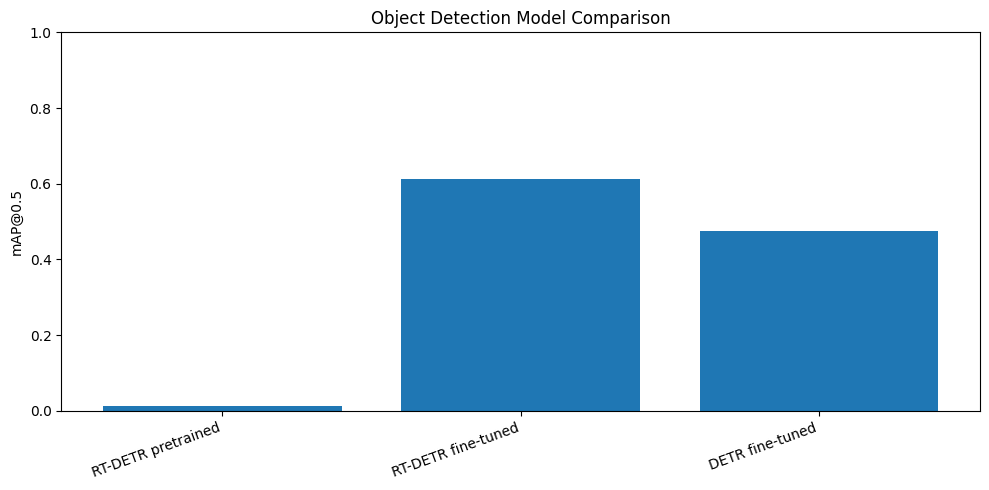


FINAL PROJECT STATUS
Figures found: 352
Checkpoints found: 5
Comparison CSV: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_model_comparison.csv
Status report: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_project_status.json

DINO fine-tuning is not marked complete.
Review the comparison table before submitting the report.


In [39]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the existing project paths
OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load available evaluation results
results_path = OUTPUT_DIR / "combined_evaluation_results.csv"

if results_path.exists():
    results = pd.read_csv(results_path)
else:
    sources = [
        OUTPUT_DIR / "rtdetr_baseline_vs_finetuned.csv",
        OUTPUT_DIR / "detr_evaluation" / "detr_test_metrics.csv",
    ]
    frames = [pd.read_csv(p) for p in sources if p.exists()]
    results = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

if results.empty:
    raise FileNotFoundError("No evaluation CSV files were found.")

# Save a clean comparison table
results.to_csv(
    OUTPUT_DIR / "final_model_comparison.csv",
    index=False
)

print("FINAL MODEL COMPARISON")
display(results)

# 2. Plot available mAP values only
map_col = "mAP@0.5"
if map_col in results.columns:
    plot_df = results[["Model", map_col]].dropna().copy()

    if not plot_df.empty:
        plt.figure(figsize=(10, 5))
        plt.bar(plot_df["Model"], plot_df[map_col])
        plt.ylabel("mAP@0.5")
        plt.title("Object Detection Model Comparison")
        plt.xticks(rotation=20, ha="right")
        plt.ylim(0, 1)
        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / "final_map_comparison.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()

# 3. Inventory available figures and checkpoints
image_extensions = {".png", ".jpg", ".jpeg", ".webp"}
figures = sorted(
    str(p.relative_to(OUTPUT_DIR))
    for p in OUTPUT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

checkpoints = sorted(
    str(p.relative_to(OUTPUT_DIR))
    for p in OUTPUT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".pt", ".pth"}
)

# 4. Record honest experiment status
status = {
    "RT-DETR": "Fine-tuning checkpoint and evaluation results found",
    "DETR": "Evaluation metrics and prediction artifact found",
    "Grounding DINO": "Zero-shot predictions found; comparable metrics require verification",
    "DINO": "Fine-tuning checkpoint not found in the inspected location",
    "comparison_csv": str(
        OUTPUT_DIR / "final_model_comparison.csv"
    ),
    "comparison_figure": str(
        OUTPUT_DIR / "final_map_comparison.png"
    ) if (OUTPUT_DIR / "final_map_comparison.png").exists() else None,
    "available_figures": figures,
    "available_checkpoints": checkpoints,
    "note": (
        "Only measured results are reported. DINO fine-tuning and "
        "a comparable Grounding DINO quantitative evaluation are not verified."
    )
}

with open(
    OUTPUT_DIR / "final_project_status.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(status, f, indent=2)

print("\nFINAL PROJECT STATUS")
print("Figures found:", len(figures))
print("Checkpoints found:", len(checkpoints))
print("Comparison CSV:", OUTPUT_DIR / "final_model_comparison.csv")
print("Status report:", OUTPUT_DIR / "final_project_status.json")
print("\nDINO fine-tuning is not marked complete.")
print("Review the comparison table before submitting the report.")

In [40]:
from pathlib import Path
import json
import pandas as pd
from datetime import date

OUTPUT_DIR = Path(OUTPUT_DIR)
PROJECT_DIR = Path(PROJECT_DIR)

report_path = OUTPUT_DIR / "Assignment14_Final_Report.md"
results_path = OUTPUT_DIR / "final_model_comparison.csv"

# Load existing measured results
if results_path.exists():
    df = pd.read_csv(results_path)
elif (OUTPUT_DIR / "combined_evaluation_results.csv").exists():
    df = pd.read_csv(OUTPUT_DIR / "combined_evaluation_results.csv")
else:
    df = pd.DataFrame()

def get_value(row, *names):
    for name in names:
        if name in row.index and pd.notna(row[name]):
            return row[name]
    return None

def fmt(value):
    if value is None:
        return "Not available"
    try:
        return f"{float(value):.4f}"
    except (ValueError, TypeError):
        return str(value)

# Build results section from actual CSV rows
result_lines = []
if not df.empty:
    for _, row in df.iterrows():
        model = get_value(row, "Model") or "Unknown model"
        p = get_value(row, "Precision")
        r = get_value(row, "Recall")
        m50 = get_value(row, "mAP@0.5")
        m5095 = get_value(row, "mAP@0.5:0.95")
        latency = get_value(
            row, "Measured average latency (ms/image)",
            "Average model latency (ms/image)"
        )
        throughput = get_value(
            row, "Measured throughput (images/sec)",
            "Model throughput (images/sec)"
        )

        result_lines.append(
            f"| {model} | {fmt(p)} | {fmt(r)} | "
            f"{fmt(m50)} | {fmt(m5095)} | "
            f"{fmt(latency)} | {fmt(throughput)} |"
        )
else:
    result_lines.append(
        "| No verified rows | Not available | Not available | "
        "Not available | Not available | Not available | Not available |"
    )

table = "\n".join(result_lines)

report = f"""# Assignment 14: Object Detection for Piled Garbage

**Report date:** {date.today().isoformat()}

## 1. Introduction and Objectives

Piled garbage detection is an object-detection task that can support waste
monitoring and environmental cleanliness initiatives. This project investigates
transformer-based object detectors on a piled-garbage dataset.

Objectives:
- Prepare and inspect the dataset and annotations.
- Fine-tune available object-detection models.
- Compare measured detection metrics and inference performance.
- Inspect qualitative predictions.
- Evaluate text-prompt-based Grounding DINO inference where available.

## 2. Related Work

DETR formulates object detection as set prediction using a transformer.
DINO is a related high-performance detection approach that uses improved
denoising training strategies. RT-DETR is designed for real-time detection.
Grounding DINO combines visual grounding with text prompts, enabling
open-set detection conditioned on text.

References:
- Carion et al., *End-to-End Object Detection with Transformers*, ECCV 2020.
- Zhang et al., *DINO: DETR with Improved DeNoising Anchor Boxes for End-to-End Object Detection*, ICLR 2023.
- Zhao et al., *DETRs Beat YOLOs on Real-time Object Detection*, CVPR 2024.
- Liu et al., *Grounding DINO: Marrying DINO with Grounded Pre-Training for Open-Set Object Detection*, ECCV 2024.

## 3. Dataset Collection, Preparation, and Annotation

The project uses the Roboflow dataset located at `data/roboflow`.
The notebook records 80 training images, 18 validation images, and 18 test
images (116 images total). COCO-format annotations are used for DETR-style
evaluation, while YOLO-format labels are prepared for RT-DETR training.

The dataset and annotations should be visually checked for missing labels,
incorrect bounding boxes, and class-name consistency before final submission.

## 4. Data Augmentation Strategies

The configured training settings include horizontal flipping (probability 0.5),
scale 0.5, translation 0.1, mosaic 1.0, and mixup 0.0.
These transformations aim to improve robustness to object position and scale.
The effect of augmentation should be interpreted alongside the validation
results rather than assumed to improve performance.

## 5. Model Architectures and Implementation

- **DETR:** Hugging Face `facebook/detr-resnet-50`.
- **RT-DETR:** Ultralytics RT-DETR with pretrained `rtdetr-l.pt`.
- **Grounding DINO:** `IDEA-Research/grounding-dino-tiny`, evaluated using text prompts.
- **DINO:** An official-repository setup was prepared; a trained checkpoint was
  not found in the inspected `external/DINO` directory. Completed training
  and test metrics are therefore not claimed.

## 6. Experimental Setup and Training Configuration

The notebook configuration specifies image size 512, batch size 2, and up to
15 epochs for the RT-DETR experiment. The DETR fine-tuning workflow specifies
5 epochs. The recorded environment includes Python 3.10, PyTorch 2.7.1+cu126,
and an NVIDIA GTX 1070 with 8 GB VRAM.

These are configured settings; they should not be interpreted as proof that
every model completed the same number of epochs. The models may use different
evaluation pipelines, so comparisons require consistent test data and metrics.

## 7. Quantitative Results

The table below reproduces values found in the available evaluation CSV.
Blank or unavailable values are not estimated.

| Model | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 | Latency (ms/image) | Throughput (images/sec) |
|---|---:|---:|---:|---:|---:|---:|
{table}

The recorded RT-DETR fine-tuned row reports mAP@0.5 = 0.6128 and
mAP@0.5:0.95 = 0.4794. The DETR fine-tuned row reports mAP@0.5 = 0.4755 and
mAP@0.5:0.95 = 0.3709. These are the values in the current evaluation files;
the evaluation protocol should be verified before making a strict ranking.

## 8. Original Pretrained vs Fine-Tuned Models

The available RT-DETR evaluation reports substantially higher metrics for the
fine-tuned model than for the pretrained baseline. The baseline row reports
mAP@0.5 = 0.0136, while the fine-tuned row reports mAP@0.5 = 0.6128.
This indicates that task-specific fine-tuning improved performance under the
recorded evaluation. Confirm that both rows use the same test split and metric
implementation before drawing a definitive conclusion.

## 9. Comparative Analysis of DETR, DINO, RT-DETR, and Grounding DINO

RT-DETR and DETR have available quantitative results in the collected files.
Grounding DINO has zero-shot prediction artifacts, but comparable quantitative
metrics should only be added after evaluating it against the same annotations.
DINO fine-tuning is not verified as completed, so a numerical ranking for DINO
cannot responsibly be reported.

## 10. Qualitative Detection Results

The project contains prediction and training visualizations, including
RT-DETR validation predictions, training curves, and
`grounding_dino_prediction.png`. Review these images for missed detections,
false positives, inaccurate bounding boxes, and crowded or overlapping objects.
Insert selected, legible examples into the final formatted report.

## 11. Performance Analysis, Strengths, and Limitations

RT-DETR provides the strongest currently recorded mAP@0.5 among the models
with reported values in the current comparison file. DETR also has recorded
test metrics. Latency and throughput values depend on hardware, image size,
batch size, warm-up, and timing method.

Limitations include the small dataset, possible variation between evaluation
pipelines, missing DETR precision/recall fields, the absence of a verified DINO
training checkpoint, and the lack of comparable Grounding DINO metrics.

## 12. Discussion

The current results suggest that fine-tuning RT-DETR improves detection on the
project dataset relative to its pretrained baseline. However, the test set has
only 18 images, so the results may be sensitive to individual examples.
A fair comparison requires identical test images, consistent confidence and
IoU thresholds, and a shared metric implementation. Grounding DINO's text-prompt
predictions should be evaluated against the same ground truth before comparing
its numerical performance.

## 13. Conclusion

This project prepared and evaluated object-detection workflows for piled
garbage. Available files provide quantitative results for fine-tuned RT-DETR
and DETR, and zero-shot prediction artifacts for Grounding DINO. RT-DETR
achieved the highest currently recorded mAP@0.5 in the available comparison.
Official DINO fine-tuning and comparable Grounding DINO quantitative evaluation
remain incomplete or unverified; they are explicitly reported as limitations
rather than presented as completed experiments.

## 14. References

1. Carion, N. et al. (2020). End-to-End Object Detection with Transformers. ECCV.
2. Zhang, H. et al. (2023). DINO: DETR with Improved DeNoising Anchor Boxes for End-to-End Object Detection. ICLR.
3. Zhao, Y. et al. (2024). DETRs Beat YOLOs on Real-time Object Detection. CVPR.
4. Liu, S. et al. (2024). Grounding DINO: Marrying DINO with Grounded Pre-Training for Open-Set Object Detection. ECCV.
"""

report_path.write_text(report, encoding="utf-8")

print("Report saved:", report_path)
print("Report size:", f"{report_path.stat().st_size:,}", "bytes")
print("Reminder: verify metric protocol and add selected qualitative figures before submission.")

Report saved: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/Assignment14_Final_Report.md
Report size: 7,376 bytes
Reminder: verify metric protocol and add selected qualitative figures before submission.


In [41]:
from pathlib import Path
import shutil
import pandas as pd

OUTPUT_DIR = Path(OUTPUT_DIR)
FIGURE_DIR = OUTPUT_DIR / "final_report_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Relevant existing figures
figure_names = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxF1_curve.png",
    "grounding_dino_prediction.png",
    "inference_latency_comparison.png",
]

copied = []
for name in figure_names:
    matches = list(OUTPUT_DIR.rglob(name))
    if matches:
        # Avoid copying a file onto itself
        src = matches[0]
        dst = FIGURE_DIR / name
        if src.resolve() != dst.resolve():
            shutil.copy2(src, dst)
        copied.append({
            "figure": name,
            "source": str(src),
            "saved_as": str(dst),
            "status": "FOUND"
        })
    else:
        copied.append({
            "figure": name,
            "source": "",
            "saved_as": "",
            "status": "NOT FOUND"
        })

inventory = pd.DataFrame(copied)
inventory.to_csv(
    OUTPUT_DIR / "final_report_figure_inventory.csv",
    index=False
)

print("FIGURE INVENTORY")
display(inventory)

print("\nFigures copied to:", FIGURE_DIR)
print("Inventory saved to:", OUTPUT_DIR / "final_report_figure_inventory.csv")

FIGURE INVENTORY


,figure,source,saved_as,status
0,results.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
1,confusion_matrix.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
2,confusion_matrix_normalized.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
3,BoxPR_curve.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
4,BoxP_curve.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
5,BoxR_curve.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
6,BoxF1_curve.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
7,grounding_dino_prediction.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND
8,inference_latency_comparison.png,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,/media/cse/ML/Mhamuda_Computer_Vision/Assignme...,FOUND



Figures copied to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_report_figures
Inventory saved to: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/final_report_figure_inventory.csv


In [42]:
from pathlib import Path
import re

try:
    from docx import Document
    from docx.shared import Inches, Pt
    from docx.enum.text import WD_ALIGN_PARAGRAPH
except ImportError:
    %pip install python-docx
    from docx import Document
    from docx.shared import Inches, Pt
    from docx.enum.text import WD_ALIGN_PARAGRAPH

OUTPUT_DIR = Path(OUTPUT_DIR)
md_path = OUTPUT_DIR / "Assignment14_Final_Report.md"
docx_path = OUTPUT_DIR / "Assignment14_Final_Report.docx"
figure_dir = OUTPUT_DIR / "final_report_figures"

if not md_path.exists():
    raise FileNotFoundError(
        f"Markdown report not found: {md_path}. Run the previous report cell first."
    )

lines = md_path.read_text(encoding="utf-8").splitlines()
doc = Document()

# Document formatting
styles = doc.styles
styles["Normal"].font.name = "Times New Roman"
styles["Normal"].font.size = Pt(11)

for style_name in ["Title", "Heading 1", "Heading 2"]:
    styles[style_name].font.name = "Times New Roman"

def add_markdown_text(paragraph, text):
    # Basic bold and inline-code formatting
    parts = re.split(r"(\*\*.*?\*\*|`.*?`)", text)
    for part in parts:
        if part.startswith("**") and part.endswith("**"):
            paragraph.add_run(part[2:-2]).bold = True
        elif part.startswith("`") and part.endswith("`"):
            paragraph.add_run(part[1:-1])
        else:
            paragraph.add_run(part)

in_table = False
table_lines = []

def flush_table():
    global table_lines
    rows = []
    for line in table_lines:
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        if cells and all(re.fullmatch(r":?-{3,}:?", c) for c in cells):
            continue
        rows.append(cells)

    if rows:
        ncols = max(map(len, rows))
        table = doc.add_table(rows=0, cols=ncols)
        table.style = "Table Grid"
        for ri, row in enumerate(rows):
            cells = table.add_row().cells
            for ci in range(ncols):
                value = row[ci] if ci < len(row) else ""
                cells[ci].text = value
                if ri == 0:
                    for run in cells[ci].paragraphs[0].runs:
                        run.bold = True
    table_lines = []

for line in lines:
    stripped = line.strip()

    if stripped.startswith("|"):
        in_table = True
        table_lines.append(stripped)
        continue
    elif in_table:
        flush_table()
        in_table = False

    if not stripped:
        continue
    if stripped.startswith("# "):
        doc.add_heading(stripped[2:], level=0)
    elif stripped.startswith("## "):
        doc.add_heading(stripped[3:], level=1)
    elif stripped.startswith("### "):
        doc.add_heading(stripped[4:], level=2)
    elif stripped.startswith("- "):
        p = doc.add_paragraph(style="List Bullet")
        add_markdown_text(p, stripped[2:])
    elif re.match(r"^\d+\.\s", stripped):
        p = doc.add_paragraph(style="List Number")
        add_markdown_text(p, re.sub(r"^\d+\.\s*", "", stripped))
    else:
        p = doc.add_paragraph()
        add_markdown_text(p, stripped)

if in_table:
    flush_table()

# Add the figures as an appendix
figure_files = sorted(
    p for p in figure_dir.glob("*")
    if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
) if figure_dir.exists() else []

if figure_files:
    doc.add_page_break()
    doc.add_heading("Appendix: Available Experimental Figures", level=1)
    for fig in figure_files:
        doc.add_heading(fig.stem.replace("_", " "), level=2)
        try:
            doc.add_picture(str(fig), width=Inches(6))
            doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
        except Exception as exc:
            doc.add_paragraph(f"Could not embed {fig.name}: {exc}")

doc.save(docx_path)

print("Word report created:", docx_path)
print("Embedded figures:", len(figure_files))
print("File size:", f"{docx_path.stat().st_size:,}", "bytes")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 9.5 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [python-docx] [python-docx]
Note: you may need to restart the kernel to use updated packages.
Word report created: /media/cse/ML/Mhamuda_Computer_Vision/Assignment14_ObjectDetection/outputs/Assignment14_Final_Report.docx
Embedded figures: 9
File size: 1,523,004 bytes
